# Recorrido del programa: del video a los parámetros del reflejo fotomotor

Este notebook corre el programa paso a paso sobre uno de nuestros registros. En cada etapa muestra cómo queda la imagen o la señal y explica por qué elegimos ese método. Usa las mismas funciones que `pipeline_completo.py` y que la aplicación, así que lo que se ve acá es lo que hace el programa.

En varias etapas, además, se prueban con los mismos frames las alternativas que descartamos (otros filtros, otros métodos de segmentación), para que quede bien respaldada nuestra elección.

| Sección | Paso del programa | Módulo | Entrada → salida |
|---|---|---|---|
| 1 | Importación | 0 | archivo de video → frames y metadatos |
| 2 | ROI y escala | 2 (manejo del ROI) | primer frame → recorte fijo y escala de los parámetros |
| 3 | Mejoramiento | 1 | recorte → gris suavizado y rango de interés |
| 4 | Segmentación | 2 | imagen mejorada → máscara y diámetro de la pupila, frame a frame |
| 5 | Curva temporal | 3 | diámetros → curva sin artefactos y suavizada |
| 6 | Estímulo y parámetros | 3 | curva y brillo → latencia, amplitud, velocidades |
| 7 | Validación | 2 y 3 | anotación manual → Dice, IoU, MAE y RMSE |

Correrlo de arriba a abajo tarda unos minutos: la sección 4 procesa el video completo y las comparaciones segmentan varias decenas de frames con cada alternativa.

## Configuración

In [1]:
VIDEO = "registro_A1.MOV"     # Video dentro de videos/
USAR_ROI_GUARDADO = True      # False: marcar el ROI de nuevo
SEGUNDOS_BASALES = 1.0        # Tramo inicial, antes del estímulo, para medir el ruido de cada alternativa
N_MUESTRAS = 60               # Frames repartidos en todo el video para las comparaciones

In [2]:
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Rectangle
from IPython.display import Image, display
from scipy import ndimage as ndi
from skimage.filters import gaussian, sobel
from skimage.morphology import disk

import pipeline_completo as pipeline
from modulos import interfaz as ui
from modulos import modulo0_importacion as m0
from modulos import modulo1_mejoramiento as m1
from modulos import modulo2_segmentacion as m2
from modulos import modulo3_caracteristicas as m3

plt.rcParams["figure.dpi"] = 110
COLORES = m1.COLORES + ["#e87ba4"]   # Paleta del proyecto; el azul es siempre lo que usa el programa
GRIS = m1.GRIS_TEXTO

ruta = pipeline.resolver_video(VIDEO)
stem = ruta.stem
print("Video:", ruta.name)

Video: registro_A1.MOV


### Funciones de apoyo del notebook

Reproducen lo que hace el programa al comienzo del seguimiento (recorte del ROI, mejoramiento, ubicación de la pupila y snake) para poder aplicarlo a frames sueltos y cambiar una pieza por vez en las comparaciones.

In [3]:
def leer_frames(indices, funcion=None, video=None):
    # Frames pedidos (BGR, o funcion(frame)): avanza leyendo si el siguiente está cerca y salta si está lejos
    frames, actual = {}, 0
    with m2.abrir_video(video or ruta) as cap:
        for i in sorted({int(i) for i in indices}):
            if i - actual > 30:
                cap.set(cv2.CAP_PROP_POS_FRAMES, i)
            else:
                for _ in range(i - actual):
                    cap.grab()
            ok, frame = cap.read()
            if not ok:
                break
            frames[i] = frame if funcion is None else funcion(frame)
            actual = i + 1
    return frames


def a_rgb(bgr):
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def recortar(frame):
    # Recorte del ROI a la resolución de procesamiento, como en el programa
    return m2.recortar(frame, prep["roi"], prep["factor"], prep["r_iris"])


def mejorar(crop, info, variante="Programa"):
    # Módulo 1 sobre el recorte, con la pupila ubicada como al comienzo del seguimiento.
    # variante: la del programa o una de las alternativas de la sección 3.4
    esc, r_ref = info["esc"], info["r_ref"]
    mejora = m1.suavizar_roi(crop, esc, color=True)
    x, y, r0 = m2.estimar_pupila(mejora["suave_ubicacion"])   # Misma ubicación para todas las variantes
    gris, k = mejora["gris"], mejora["ventana"]
    if variante == "CLAHE antes del suavizado":
        gris = m1.ecualizar_clahe(gris)
        mejora.update(gris=gris, suave=cv2.GaussianBlur(gris, (k, k), 0))
    elif variante == "Sin suavizar":
        mejora["suave"] = gris
    elif variante == "Mediana":
        mejora["suave"] = cv2.medianBlur(gris, k)
    mejora = m1.realzar_pupila(mejora, esc, (x, y), r_ref)   # F2 sobre el suavizado de cada variante
    if mejora["umbral"] is not None:
        recortada = np.minimum(gris, mejora["umbral"])
        if variante == "Sin suavizar":
            mejora["realzada"] = recortada / 255.0
        elif variante == "Mediana":
            mejora["realzada"] = cv2.medianBlur(recortada, k) / 255.0
    if variante == "Gaussiano sin rango de interés":
        mejora["realzada"] = gaussian(gris / 255.0, sigma=esc, preserve_range=True)
    return mejora, (x, y, r0)


def segmentar_snake(mejora, ubicacion, info):
    # Snake + morfología del programa (módulo 2); devuelve la máscara y el contorno subpíxel
    x, y, r0 = ubicacion
    mascara = m2.segmentar_frame(mejora, (x, y), info["esc"], r0=r0)
    return mascara, m2.segmentar_frame.snake


def ruido_cv(d):
    # Coeficiente de variación (%) de los diámetros válidos
    d = pd.Series(d).dropna()
    return 100 * d.std() / d.mean() if len(d) > 2 else np.nan


def ejes(eje):
    m1._ejes_recesivos(eje)
    eje.grid(axis="x", color=m1.GRIS_GRILLA, linewidth=0.8)

## 1. Importación del video (Módulo 0)

El video se abre con OpenCV. Las dimensiones se toman del primer frame y no del encabezado, porque los celulares guardan la orientación aparte y el encabezado puede tener el ancho y el alto invertidos. Si el archivo no informa los fps se supone 30.

Todos los tiempos del programa (ventanas de filtros, márgenes, duraciones) están definidos en segundos y se pasan a frames con los fps del video. Así el comportamiento es el mismo a 30, 60 o 120 fps.

─────────────────────────────────────────────
Video            : D:\Datos Facu No Borrar\Escritorio\Guía imágenes PSIB\videos\registro_A1.MOV
Resolución       : 2160 x 3840 px
Canales          : 3
Frecuencia       : 119.83 fps
Cantidad frames  : 3122
Duración         : 26.05 s
Códec            : hevc
─────────────────────────────────────────────


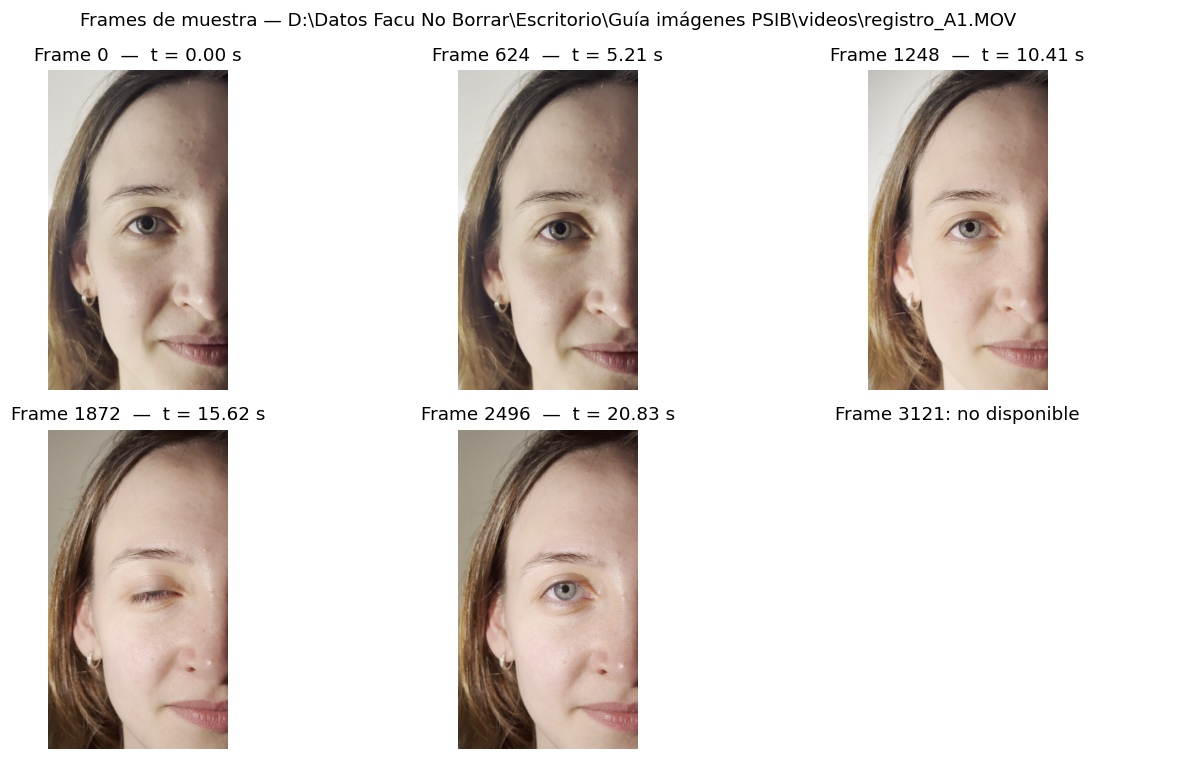

In [4]:
video, metadatos = m0.abrir_video(ruta)
m0.imprimir_metadatos(metadatos)
m0.mostrar_frames_muestra(video, metadatos)
video.release()
fps, total = metadatos["fps"], metadatos["cantidad_frames"]

**Análisis** . El registro A es un video vertical de 2160 × 3840 px (4K), grabado a 119,83 fps con códec HEVC, de 26 s de duración. El encabezado informa 3122 frames, pero el último no se puede leer (aparece como “no disponible”), y el módulo 2 terminó procesando 3118. Los .MOV suelen informar en el encabezado algunos frames de más; por eso el programa lee hasta que el video se termina en lugar de confiar en ese número.

**Cómo definimos la ROI**

Lo primero que vemos es que la cara quedó aproximadamente en el mismo lugar del cuadro en todos los frames de muestra. Y esto nos fue de utilidad para definir el ROI: inicialmente, habíamos propuesto diseñar un algoritmo que ubica a la pupila en el centro del frame (de alguna manera), y que defina la ROI una cierta cantidad de pixeles alrededor de esa coordenada. El problema con esto era que no sabíamos qué tan cerca del ojo se tomaría el video a analizar, por lo que habría que además diseñar un algoritmo de "detección de la región alrededor del ojo", para definir la ROI.

Por otro lado, no usamos detección automática del ojo (como clasificadores de Haar o modelos entrenados) porque agregaría una fuente de error que no controlamos, y porque se había indicado en la consigna que no usáramos herramientas de IA.

Sin embargo, al analizar los frames de muestra vemos que la cabeza se mantiene relativamente estática. Asumiendo que el video que van a usar para la corrección también va a cumplir esto, es suficiente con poner una instancia de selección manual de la ROI, en base al primer frame (ver nota al final), y que esa ROI se mantenga a lo largo del video. De todos modos, en caso de que luego de hacer la segmentación de la pupila, se detecte que quedó por fuera de la ROI, se marca ese frame como no útil.

Nota: Podría ocurrir que el primer frame no tenga una correcta apreciación del ojo (ya sea porque inicia pestañeando, o porque el primer frame tuvo algún artefacto), por lo que en la aplicación se agregó la opción de avanzar entre frames hasta seleccionar el deseado y recién ahí seleccionar la ROI.

## 2. ROI y escala

**Escala de los parámetros.** Los tamaños de filtros, elementos estructurantes y fuerzas de la snake están definidos para un iris de 32 px de radio y se multiplican por esc = r<sub>iris</sub> / 32. Así los mismos parámetros sirven para un video de 720p o de 4K. El radio de iris de referencia no se midió, sino que se estimó brutamente con la pupila de 10 frames de los primeros 2 s (la mediana descarta un parpadeo) dividida por 0,45, el cociente típico pupila/iris. Solo importa su orden de magnitud; por eso no lo usamos para pasar los resultados a milímetros.

**Resolución de procesamiento.** Si el iris queda de más de 64 px de radio, el recorte se reduce con `INTER_AREA`, que promedia los píxeles y no genera aliasing.

ROI: x=731 y=1575 1006x579 px (roi.json); escala de parámetros = 7.24
Escala: radio de pupila al comienzo ≈ 68.0 px -> radio de iris de referencia ≈ 151 px (mediana de 10 frames)
Resolución de procesamiento: 42 % del video original (radio de iris ≈ 64 px)


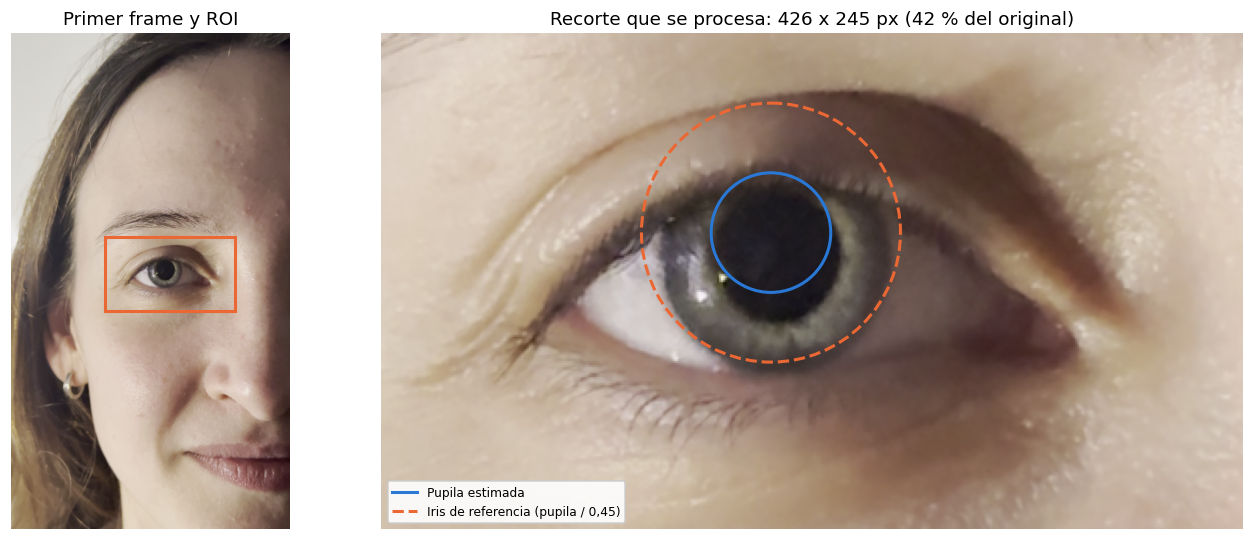

In [5]:
prep = m2.preparar(ruta, nuevo_roi=m2.PEDIR_ROI_SIEMPRE and not USAR_ROI_GUARDADO)
roi = prep["roi"]
frame0 = leer_frames([0])[0]
recorte0, info0 = recortar(frame0)
mejora0, ubic0 = mejorar(recorte0, info0)
x0, y0, rp0 = ubic0

alto_f, ancho_f = frame0.shape[:2]
alto_r, ancho_r = recorte0.shape[:2]
fig, (eje_f, eje_r) = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained",
                                   width_ratios=[ancho_f / alto_f, ancho_r / alto_r])
eje_f.imshow(a_rgb(frame0))
eje_f.add_patch(Rectangle((roi.x0, roi.y0), roi.w, roi.h, fill=False, edgecolor=COLORES[1], linewidth=2))
eje_f.set_title("Primer frame y ROI")
eje_r.imshow(a_rgb(recorte0))
eje_r.add_patch(Circle((x0, y0), rp0, fill=False, edgecolor=COLORES[0], linewidth=2))
eje_r.add_patch(Circle((x0, y0), info0["r_ref"], fill=False, edgecolor=COLORES[1], linewidth=2, linestyle="--"))
eje_r.legend(handles=[Line2D([], [], color=COLORES[0], lw=2, label="Pupila estimada"),
                      Line2D([], [], color=COLORES[1], lw=2, ls="--", label="Iris de referencia (pupila / 0,45)")],
             loc="lower left", fontsize=8, framealpha=0.9)
eje_r.set_title(f"Recorte que se procesa: {ancho_r} x {alto_r} px ({100 * prep['factor']:.0f} % del original)")
for eje in (eje_f, eje_r):
    eje.axis("off")
plt.show()

**¿Cuánto cambia el diámetro por procesar a menor resolución?** Se segmenta el primer frame a resolución original y a la del programa, y se compara el diámetro (en píxeles del video original) y el tiempo.

In [6]:
filas_res = []
for nombre, factor in [("Original", 1.0), ("La del programa", prep["factor"])]:
    crop, info = m2.recortar(frame0, roi, factor, prep["r_iris"])
    inicio = time.perf_counter()
    mejora, ubic = mejorar(crop, info)
    mascara, snake = segmentar_snake(mejora, ubic, info)
    segundos = time.perf_counter() - inicio
    d = m2.ancho_horizontal(snake) / factor if snake is not None else np.nan
    filas_res.append({"Resolución": nombre, "Recorte (px)": f"{crop.shape[1]} x {crop.shape[0]}",
                      "Diámetro (px del video)": round(d, 2), "Tiempo por frame (s)": round(segundos, 3)})
tabla_res = pd.DataFrame(filas_res).set_index("Resolución")
display(tabla_res)
d_orig, d_prog = tabla_res["Diámetro (px del video)"]
print(f"Diferencia de diámetro: {100 * (d_prog - d_orig) / d_orig:+.2f} %")
if prep["factor"] == 1:
    print("El iris ya mide menos de 64 px de radio: el programa no reduce este video.")

,Recorte (px),Diámetro (px del video),Tiempo por frame (s)
Resolución,,,
Original,1006 x 579,135.62,1.686
La del programa,426 x 245,142.47,0.068


Diferencia de diámetro: +5.05 %


**Análisis.** 

El ROI marcado abarca todo el ojo, con los párpados, las pestañas y parte de la sombra del pliegue palpebral, que es bastante más que sólo el iris con un margen. Pero esto no es un problema para el mejoramiento ya que F2 se calcula en un vecindario alrededor de la pupila.

La pupila estimada (círculo azul) coincide bien con la pupila real. El círculo de iris de referencia, en cambio, es claramente más grande que el iris. En este frame la pupila mide alrededor del 60 % del iris, no el 45 % que supone el programa, porque al comienzo del registro está bastante dilatada. El radio de iris queda sobreestimado en aproximadamente un 30 %. Para el procesamiento no importa, porque solo fija el tamaño de los filtros y un error de ese orden no cambia su comportamiento. Sí confirma que ese radio no sirve para pasar los resultados a milímetros.

Procesar el recorte al 42 % de la resolución original (426 × 245 px en lugar de 1006 × 579 px) reduce el tiempo de segmentar un frame de 1,69 s a 0,068 s, unas 25 veces menos. En los 3118 frames del video son unos 3,5 min contra casi 90 min, solo de segmentación. El costo es que el diámetro de este frame pasa de 135,6 a 142,5 px (+5 %).

## 3. Mejoramiento (Módulo 1)

### 3.1 Qué hace el programa

Cada frame pasa por dos etapas antes de segmentarse:

1. **Escala de grises y suavizado gaussiano.** La pupila es oscura en los tres canales; el gris (luminancia) los promedia y tiene menos ruido que un canal solo, por lo que decidimos trabajar con la escala de grises.
2. **Rango de interés [0, F2].** Es el escalado por rango de interés de la sección 1.2, donde todo lo más claro que F2 queda en F2. F2 es el umbral inferior de Otsu multinivel con tres clases (pupila / iris oscuro y párpado / iris claro y piel), calculado en un vecindario de ±1,25 radios de iris alrededor de la pupila. En un ROI grande la pupila pasaría a ser una fracción chica de los píxeles y el histograma completo no la separaría correctamente; por eso se usa el vecindario.

La segmentación recibe las dos imágenes: el suavizado, para los umbrales, y la imagen con el rango de interés, para la snake. La figura es la misma que el programa guarda en `resultados/resultados_modulo1/` (el recuadro punteado es el vecindario donde se calcula F2).

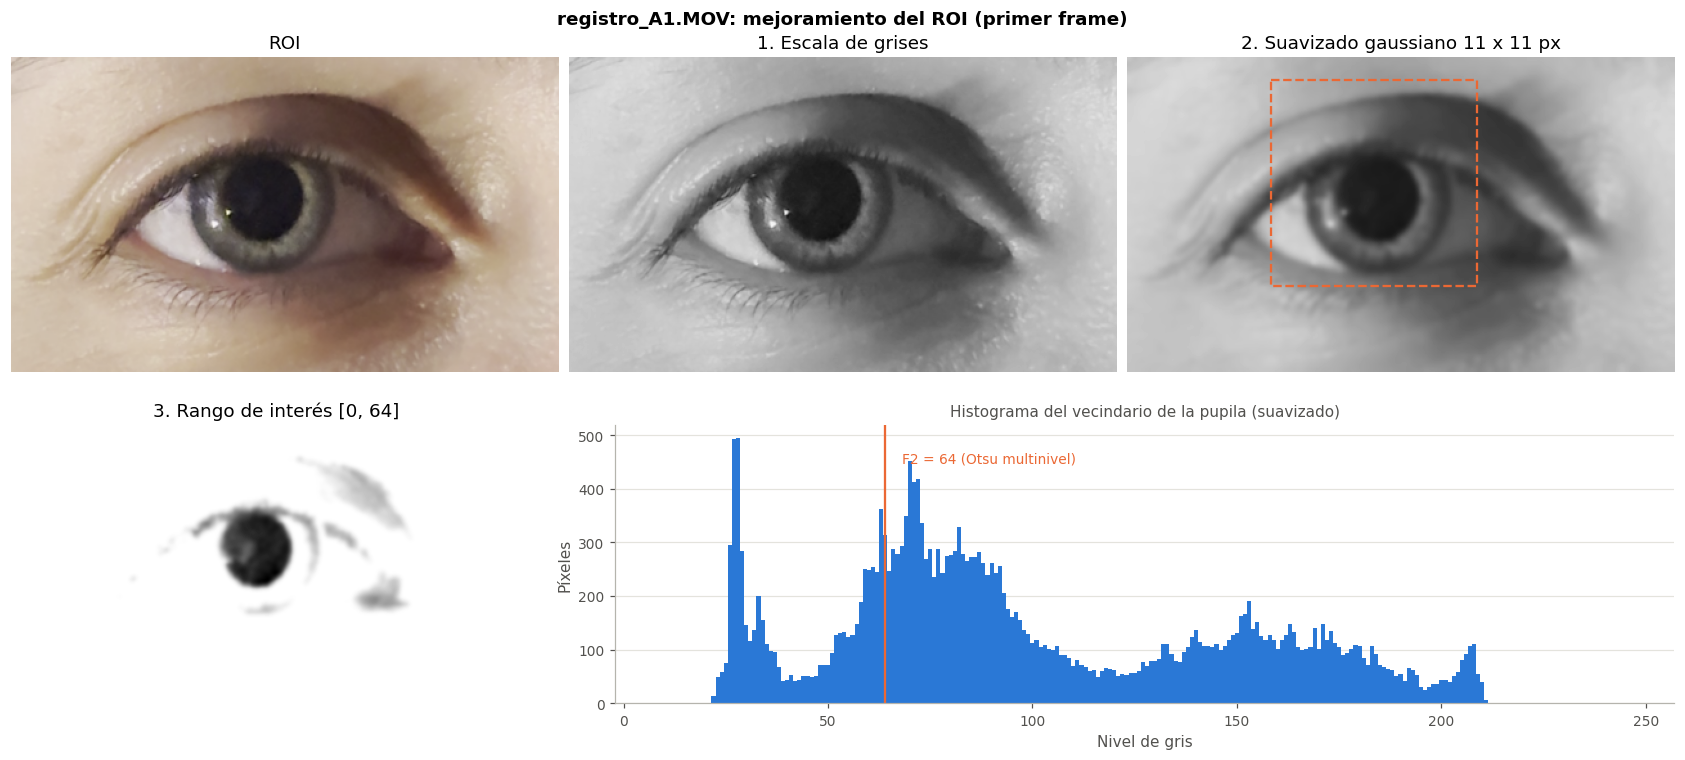

In [7]:
recorte_m1, mejora_m1, _ = m2.frame_mejorado(ruta, prep)   # Exactamente lo que muestra el paso 2 del programa
m1.mostrar_mejoramiento(recorte_m1, mejora_m1, titulo=f"{ruta.name}: mejoramiento del ROI (primer frame)")

**Análisis.** En escala de grises la pupila es la región más oscura y se separa bien del iris, que tiene niveles intermedios; la esclerótica y la piel quedan claras. El reflejo corneal es un punto blanco chico en el borde inferior izquierdo de la pupila, y hay otros reflejos sobre el párpado inferior. El suavizado gaussiano de 11 × 11 px borra el ruido y la textura de la piel y del iris, atenúa el reflejo y le quita definición a las pestañas. Sin embargo, el borde de la pupila sigue siendo nítido.

El histograma del vecindario tiene tres partes:

* un pico angosto alrededor de 25 (la pupila);
* un conjunto amplio entre 65 y 100 (iris, pestañas y sombra del párpado);
* una cola hasta 210 (esclerótica y piel).

El método de Otsu multinivel ubicó, para este caso, F2 en 64 y no en el valle (ubicado un poco antes de 50). Por eso la clase oscura incluye también las partes más oscuras del iris y las pestañas. Aun así, entre la pupila y F2 hay casi 40 niveles de diferencia. En la imagen con el rango de interés, la pupila queda como un disco negro de borde bien definido sobre fondo blanco. Lo único oscuro que sobrevive aparte son las pestañas del párpado superior y la sombra del inferior, y las dos quedan afuera del contorno inicial de la snake.

Como ya explicamos en el notebook de análisis del módulo 1, inicialmente probamos de ubicar a F2 sobre el valle antes de 50, y tomar el rango más restrictivo posible para definir bien la pupila. Sin embargo, en la práctica terminó pasando que los bordes de la pupila aparecían desdibujados, y eso afectaba directamente a su segmentación. Por lo tanto, se optó por tomar un rango un poco más permisivo.

### 3.2 Por qué el rango de interés

La snake se mueve hacia donde el gradiente de la imagen es grande. En el gris suavizado hay varios bordes fuertes además del de la pupila: el limbo (iris–esclerótica), el párpado y las pestañas. Si la snake parte cerca de uno de ellos, se queda ahí. Al saturar todo lo que supera F2, esas zonas quedan planas y el único borde fuerte que sobrevive es el de la pupila.

Para medirlo, se calcula qué fracción de la magnitud del gradiente (Sobel) cae en una banda de 2 px·esc alrededor del contorno de la pupila, antes y después del rango de interés.

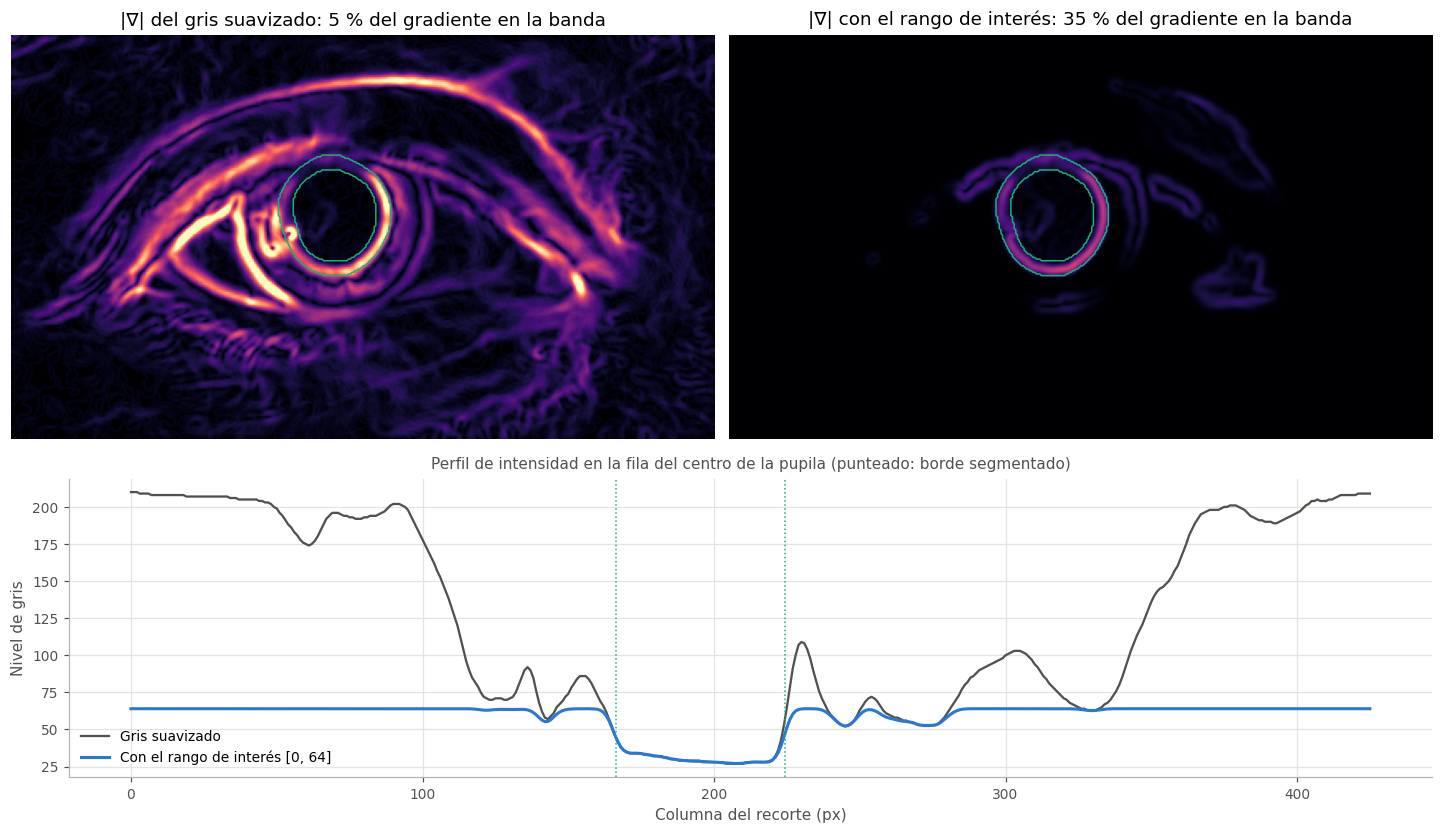

La banda ocupa el 1.6 % de los píxeles del recorte


In [8]:
mascara0, snake0 = segmentar_snake(mejora0, ubic0, info0)
if mascara0 is None:
    raise RuntimeError("No se encontró la pupila en el primer frame: revisar el ROI")
grad_suave = sobel(mejora0["suave"] / 255.0)
grad_realce = sobel(mejora0["realzada"])
borde = mascara0 ^ ndi.binary_erosion(mascara0)
banda = ndi.binary_dilation(borde, disk(m2.px(2, info0["esc"])))

fig = plt.figure(figsize=(13, 7.4), layout="constrained")
arriba, abajo = fig.subfigures(2, 1, height_ratios=[1.15, 1])
ej = arriba.subplots(1, 2)
tope = np.percentile(grad_suave, 99.5)
for eje, g, titulo in zip(ej, (grad_suave, grad_realce), ("|∇| del gris suavizado", "|∇| con el rango de interés")):
    eje.imshow(g, cmap="magma", vmin=0, vmax=tope)   # Misma escala en los dos
    eje.contour(banda, levels=[0.5], colors=[COLORES[2]], linewidths=1)
    eje.set_title(f"{titulo}: {100 * g[banda].sum() / g.sum():.0f} % del gradiente en la banda")
    eje.axis("off")
eje = abajo.subplots()
fila = int(round(y0))
eje.plot(mejora0["suave"][fila], color=GRIS, lw=1.5, label="Gris suavizado")
eje.plot(mejora0["realzada"][fila] * 255, color=COLORES[0], lw=2, label=f"Con el rango de interés [0, {mejora0['umbral']}]")
for x in np.flatnonzero(np.diff(mascara0[fila].astype(int))):
    eje.axvline(x + 0.5, color=COLORES[2], lw=1, ls=":")
eje.set_title("Perfil de intensidad en la fila del centro de la pupila (punteado: borde segmentado)", fontsize=10, color=GRIS)
eje.set_xlabel("Columna del recorte (px)", color=GRIS)
eje.set_ylabel("Nivel de gris", color=GRIS)
eje.legend(frameon=False, fontsize=9)
ejes(eje)
plt.show()
print(f"La banda ocupa el {100 * banda.mean():.1f} % de los píxeles del recorte")

**Análisis.** _[completar con nuestros resultados: qué bordes desaparecen con el rango de interés y cuánto aumenta la fracción del gradiente en el borde de la pupila]_

### 3.3 Por qué F2 se recalcula en cada frame (y por qué no ecualizamos)

En la sección 1.2 el rango de interés se fijó a mano sobre un frame. En el video eso no alcanza: cuando se enciende la luz todo el histograma se desplaza, y un F2 elegido en el primer frame deja de separar la pupila del iris. Por eso F2 se recalcula en cada frame con Otsu multinivel.

Tampoco usamos ecualización global ni CLAHE: las dos reasignan los niveles según el contenido de cada frame, de modo que el mismo tejido cambia de nivel de un frame a otro, y en las zonas uniformes (la pupila, la esclerótica) amplifican el ruido, como se vio en 1.2. En la sección 3.4 se mide además qué pasa con la segmentación si se aplica CLAHE.

Se calcula F2 y el brillo medio del ROI en frames repartidos en todo el video.

60 frames consecutivos al comienzo (0.50 s) y 59 repartidos en el video


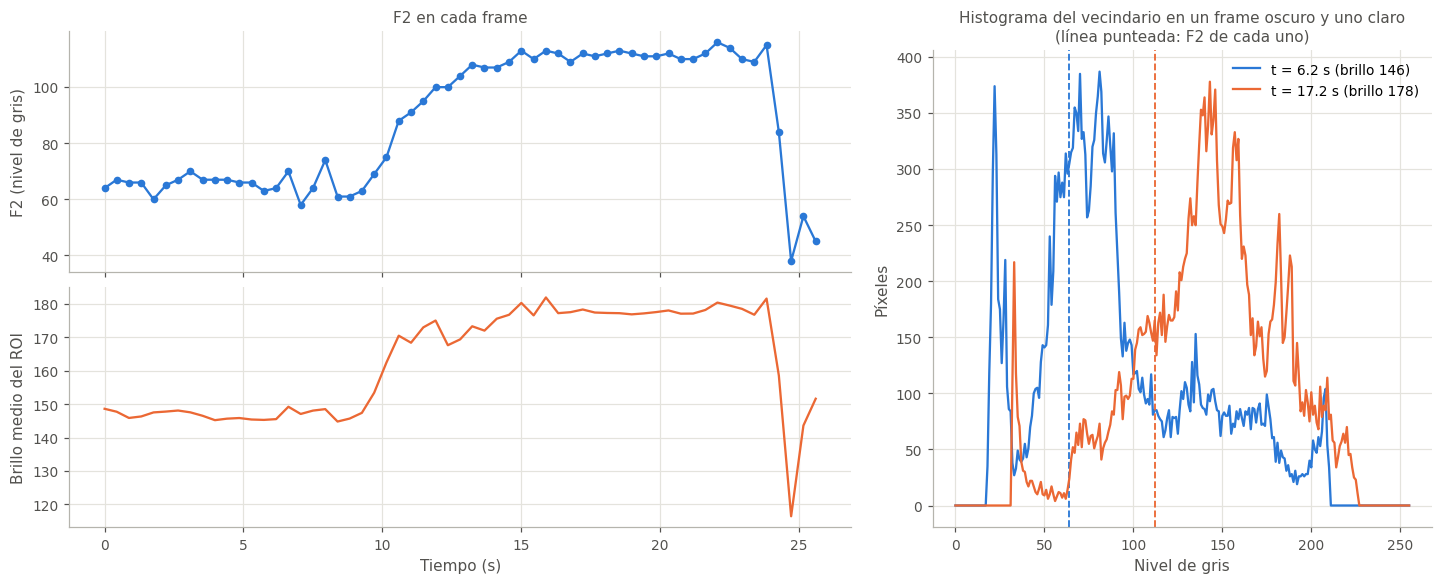

In [9]:
basales = list(range(min(int(round(SEGUNDOS_BASALES * fps)), 60, total)))
muestras = np.unique(np.linspace(0, total - 1, N_MUESTRAS).astype(int)).tolist()
recortes_basales = leer_frames(basales, funcion=recortar)
recortes_muestras = leer_frames(muestras, funcion=recortar)
print(f"{len(recortes_basales)} frames consecutivos al comienzo ({len(recortes_basales) / fps:.2f} s) "
      f"y {len(recortes_muestras)} repartidos en el video")

filas_f2 = []
for i, (crop, info) in recortes_muestras.items():
    mejora, _ = mejorar(crop, info)
    filas_f2.append({"frame": i, "t": i / fps, "F2": mejora["umbral"], "brillo": mejora["gris"].mean(), "mejora": mejora})
f2 = pd.DataFrame(filas_f2)
f2["F2"] = pd.to_numeric(f2.F2)   # None (sin contraste) -> NaN

fig = plt.figure(figsize=(13, 5.2), layout="constrained")
izq, der = fig.subfigures(1, 2, width_ratios=[1.5, 1])
e1, e2 = izq.subplots(2, 1, sharex=True)
e1.plot(f2.t, f2.F2, "-o", color=COLORES[0], ms=4, lw=1.5)
e1.set_ylabel("F2 (nivel de gris)", color=GRIS)
e1.set_title("F2 en cada frame", fontsize=10, color=GRIS)
e2.plot(f2.t, f2.brillo, color=COLORES[1], lw=1.5)
e2.set_ylabel("Brillo medio del ROI", color=GRIS)
e2.set_xlabel("Tiempo (s)", color=GRIS)
for eje in (e1, e2):
    ejes(eje)

eje = der.subplots()
# Un frame oscuro y uno claro (percentiles 10 y 90 del brillo: un parpadeo aislado no los cambia)
cercano = lambda q: f2.loc[(f2.brillo - f2.brillo.quantile(q)).abs().idxmin()]
for color, fila in zip(COLORES, (cercano(0.1), cercano(0.9))):
    x0v, y0v, x1v, y1v = fila.mejora["vecindario"]
    h = m1.histograma(fila.mejora["suave"][y0v:y1v, x0v:x1v])
    eje.plot(np.arange(256), h, color=color, lw=1.5, label=f"t = {fila.t:.1f} s (brillo {fila.brillo:.0f})")
    if np.isfinite(fila.F2):
        eje.axvline(fila.F2, color=color, ls="--", lw=1.2)
eje.set_title("Histograma del vecindario en un frame oscuro y uno claro\n(línea punteada: F2 de cada uno)",
              fontsize=10, color=GRIS)
eje.set_xlabel("Nivel de gris", color=GRIS)
eje.set_ylabel("Píxeles", color=GRIS)
eje.legend(frameon=False, fontsize=9)
ejes(eje)
plt.show()

**Análisis.** _[completar con nuestros resultados: cuánto cambia F2 entre antes y después del estímulo, y si un F2 fijo del primer frame habría quedado dentro del iris o de la pupila]_

### 3.4 Por qué suavizado gaussiano: comparación con las alternativas

Se corre la segmentación del programa (snake, morfología y control de calidad) cambiando solo el mejoramiento:

| Variante | Suavizado | Imagen que recibe la snake |
|---|---|---|
| **Programa** | gaussiano | rango de interés, suavizado |
| Sin suavizar | ninguno | rango de interés, sin suavizar |
| Mediana | mediana del mismo tamaño | rango de interés con mediana |
| Gaussiano sin rango de interés | gaussiano | gris suavizado, sin saturar |
| CLAHE antes del suavizado | CLAHE + gaussiano | rango de interés, suavizado |

Se mide sobre dos conjuntos de frames:

- **Tramo basal** (frames consecutivos del comienzo, antes del estímulo): el diámetro real casi no cambia, así que su variación es sobre todo ruido de la segmentación. Se informa como coeficiente de variación; incluye también la oscilación fisiológica de la pupila (hippus), que es igual para todas las variantes.
- **Frames repartidos en todo el video:** muestra si cada variante sigue la respuesta y en cuántos frames el control de calidad acepta la segmentación.

Lo que esperamos, y que la tabla tiene que confirmar o no: la fuerza externa de la snake es el gradiente, y el gaussiano lo ensancha alrededor del borde, así que la snake lo "siente" desde más lejos (rango de captura). La mediana conserva el borde nítido pero de alcance corto, y deja mesetas sin gradiente donde la snake solo se contrae por su elasticidad. Sin suavizado, el ruido del sensor y la textura del iris generan gradientes espurios donde la snake se puede trabar.

,Válidos (%),Ruido en el tramo basal (CV %),Tiempo por frame (ms)
Programa,96.64,1.73,55.70
Sin suavizar,96.64,2.31,67.73
Mediana,97.48,2.06,89.07
Gaussiano sin rango de interés,80.67,1.87,102.03
CLAHE antes del suavizado,95.80,2.76,59.21


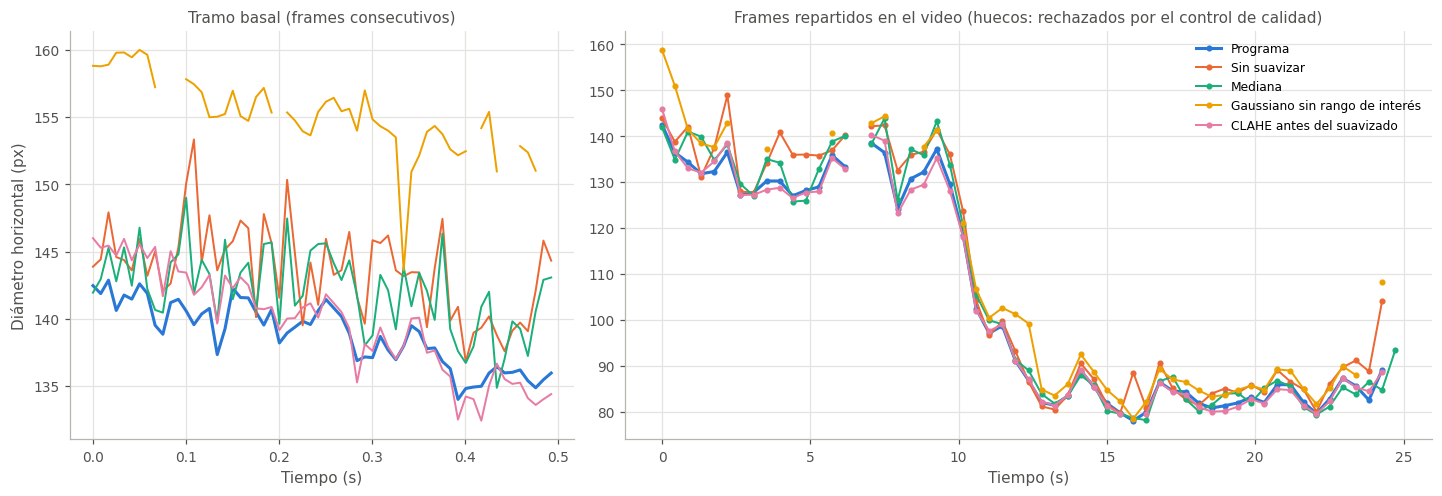

In [10]:
VARIANTES = ["Programa", "Sin suavizar", "Mediana", "Gaussiano sin rango de interés", "CLAHE antes del suavizado"]


def evaluar_variante(variante, recortes):
    filas = []
    for i, (crop, info) in recortes.items():
        inicio = time.perf_counter()
        mejora, ubic = mejorar(crop, info, variante)
        mascara, snake = segmentar_snake(mejora, ubic, info)
        ms = 1000 * (time.perf_counter() - inicio)
        valido = m2.calidad(mascara, mejora, info["r_ref"])[0]
        d = m2.ancho_horizontal(snake) / prep["factor"] if valido and snake is not None else np.nan
        filas.append({"frame": i, "t": i / fps, "valido": valido, "d": d, "ms": ms})
    return pd.DataFrame(filas)


res_var = {v: (evaluar_variante(v, recortes_basales), evaluar_variante(v, recortes_muestras)) for v in VARIANTES}
tabla_var = pd.DataFrame({v: {"Válidos (%)": 100 * pd.concat([b, m]).valido.mean(),
                              "Ruido en el tramo basal (CV %)": ruido_cv(b.d),
                              "Tiempo por frame (ms)": pd.concat([b, m]).ms.median()}
                          for v, (b, m) in res_var.items()}).T.round(2)
display(tabla_var)

fig, (e1, e2) = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained", width_ratios=[1, 1.6])
for color, (v, (b, m)) in zip(COLORES, res_var.items()):
    e1.plot(b.t, b.d, "-", color=color, lw=2 if v == "Programa" else 1.3, label=v)
    e2.plot(m.t, m.d, "-o", color=color, ms=3, lw=2 if v == "Programa" else 1.3, label=v)
e1.set_title("Tramo basal (frames consecutivos)", fontsize=10, color=GRIS)
e2.set_title("Frames repartidos en el video (huecos: rechazados por el control de calidad)", fontsize=10, color=GRIS)
e1.set_ylabel("Diámetro horizontal (px)", color=GRIS)
for eje in (e1, e2):
    eje.set_xlabel("Tiempo (s)", color=GRIS)
    ejes(eje)
e2.legend(frameon=False, fontsize=8, loc="best")
plt.show()

**Análisis.** _[completar con nuestros resultados: qué variante tiene menos ruido en el tramo basal y más frames válidos; qué le pasa a la snake sin el rango de interés (¿se va al limbo?); si CLAHE o la mediana mejoran o empeoran algo; costo en tiempo]_

## 4. Segmentación (Módulo 2)

### 4.1 Lo que hace el programa en cada frame

1. Módulo 1, primera etapa: gris y suavizado.
2. En el primer frame, o si el anterior fue inválido, se ubica la pupila: el punto más oscuro de la imagen suavizada (dentro de la elipse inscripta en el ROI y cerca de la última posición válida), un umbral a mitad de camino entre ese punto y la mediana del ROI, y el mayor círculo inscripto en la zona oscura. El círculo inscripto no se agranda con pestañas o sombras finas pegadas a la pupila.
3. Módulo 1, segunda etapa: rango de interés con F2 calculado alrededor de la pupila.
4. Snake: parte de un círculo de 1,3 veces la pupila estimada o, si el frame anterior fue válido, del contorno anterior agrandado un 25 %. Usar el contorno anterior da continuidad temporal y evita volver a ubicar la pupila en cada frame.
5. Morfología sobre la máscara de la snake (sección 4.5).
6. Control de calidad (sección 4.6).
7. Medida: ancho horizontal máximo de la snake, con precisión subpíxel, y diámetro equivalente al área.

Al final se marcan como atípicos los diámetros que se apartan más de un 15 % de la mediana móvil de 0,3 s (en ese tiempo la pupila no cambia tanto). Esta celda corre el módulo 2 completo sobre el video, igual que el paso 3 del programa.

In [11]:
filas, r_iris = m2.ejecutar_modulo2(ruta, preparacion=prep)
serie = pd.DataFrame(filas)
serie["motivo_corto"] = serie["motivo"].fillna("").str.replace(r"\s*\(.*\)", "", regex=True).replace("", "válido")

Video: registro_A1.MOV
Resultados anteriores del módulo 2 borrados
Video: 3122 frames a 119.83 fps (26.1 s). Procesando...
  overlay a 119.83 fps (el video original tiene 119.83495 fps)
  frame 1/3122 (0 %)  faltan ~1631 s  ok
  frame 21/3122 (1 %)  faltan ~391 s  ok
  frame 41/3122 (1 %)  faltan ~352 s  ok
  frame 61/3122 (2 %)  faltan ~337 s  ok
  frame 82/3122 (3 %)  faltan ~324 s  ok
  frame 103/3122 (3 %)  faltan ~318 s  ok
  frame 124/3122 (4 %)  faltan ~311 s  ok
  frame 144/3122 (5 %)  faltan ~307 s  ok
  frame 165/3122 (5 %)  faltan ~304 s  ok
  frame 186/3122 (6 %)  faltan ~300 s  ok
  frame 207/3122 (7 %)  faltan ~297 s  ok
  frame 228/3122 (7 %)  faltan ~294 s  ok
  frame 249/3122 (8 %)  faltan ~291 s  ok
  frame 270/3122 (9 %)  faltan ~288 s  ok
  frame 291/3122 (9 %)  faltan ~286 s  ok
  frame 313/3122 (10 %)  faltan ~282 s  ok
  frame 334/3122 (11 %)  faltan ~279 s  ok
  frame 355/3122 (11 %)  faltan ~277 s  ok
  frame 377/3122 (12 %)  faltan ~273 s  ok
  frame 398/3122 

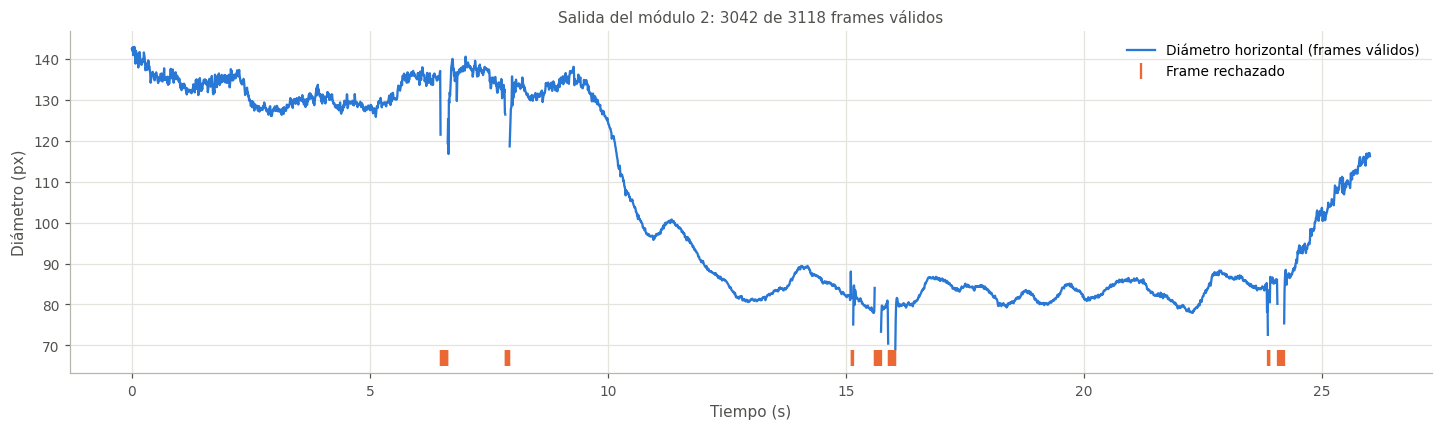

,Frames
motivo_corto,
válido,3042
atípico,33
sin pupila,21
poco contraste con el iris,15
poco circular,7


In [12]:
fig, eje = plt.subplots(figsize=(13, 3.8), layout="constrained")
eje.plot(serie.t, serie.d_pupila_px, color=COLORES[0], lw=1.5, label="Diámetro horizontal (frames válidos)")
invalidos = serie[serie.valido == 0]
base = np.nanmin(serie.d_pupila_px) * 0.97
eje.plot(invalidos.t, np.full(len(invalidos), base), "|", color=COLORES[1], ms=10, mew=1.5, label="Frame rechazado")
eje.set_xlabel("Tiempo (s)", color=GRIS)
eje.set_ylabel("Diámetro (px)", color=GRIS)
eje.set_title(f"Salida del módulo 2: {(serie.valido == 1).sum()} de {len(serie)} frames válidos", fontsize=10, color=GRIS)
eje.legend(frameon=False, fontsize=9)
ejes(eje)
plt.show()
display(serie["motivo_corto"].value_counts().rename("Frames").to_frame())

**Análisis.** _[completar con nuestros resultados: porcentaje de frames válidos, en qué momentos se concentran los rechazos (parpadeos, estímulo) y por qué motivo]_

### 4.2 Métodos de la consigna sobre el frame de trabajo (2.1)

El programa elige como frame de trabajo uno válido, sin rechazos a ±0,1 s y con la pupila más circular, y le aplica los métodos de 2.1. Parte de la pupila que encontró el seguimiento en ese frame, y todos usan la salida del módulo 1:

- **Otsu global:** umbral que maximiza la varianza entre clases, sobre todo el ROI suavizado. Se muestra sin post-procesar para ver qué se lleva además de la pupila.
- **Otsu multinivel (3 clases):** el umbral inferior separa la pupila; se conserva la componente conexa que contiene la semilla.
- **K-means (K = 2 a 5):** agrupa los píxeles en el espacio Lab suavizado (L de intensidad y a, b de croma con peso 0,5); la pupila es el grupo de menor L.
- **Snake:** sobre la imagen con el rango de interés.
- **Watershed:** inundación sobre el gradiente de Sobel con marcadores: 1 = núcleo de la pupila, 2 = fondo, 3 = reflejos (por encima del percentil 99).

Las figuras son las que guarda el programa en `resultados/resultados_modulo2/resultados_imagen/` (sin anotación manual, Dice e IoU quedan en `nan`).

registro_A1_frame_2935_21_metodos.png


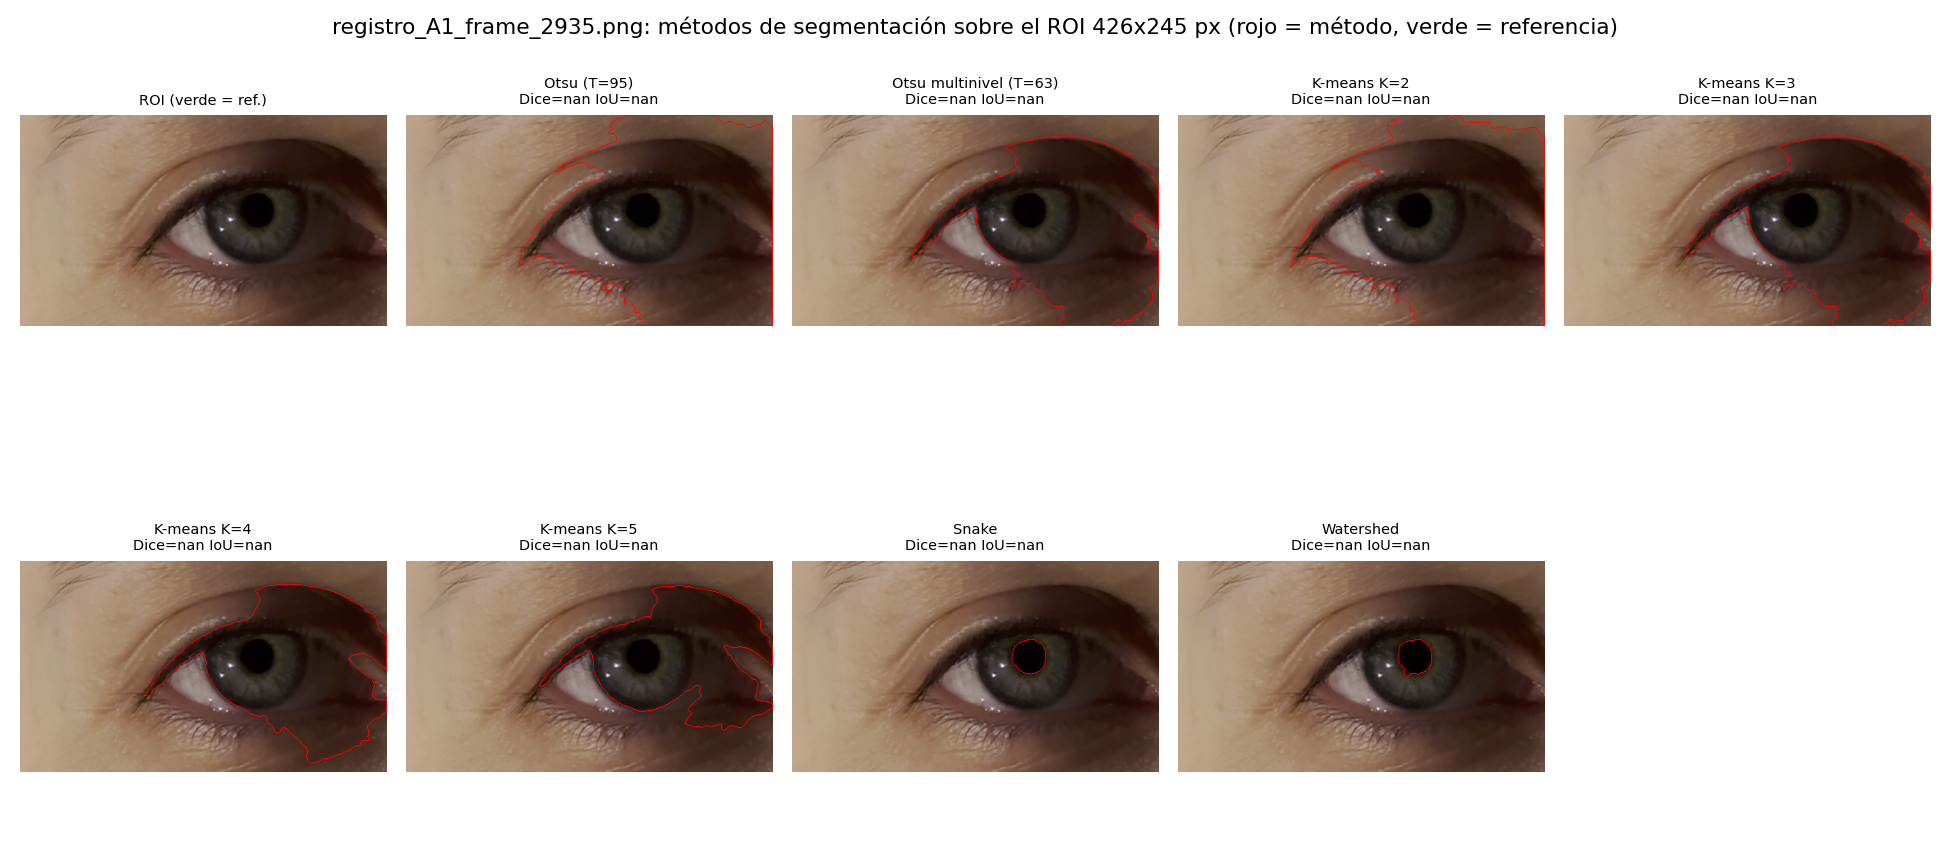

registro_A1_frame_2935_21_diagnostico.png


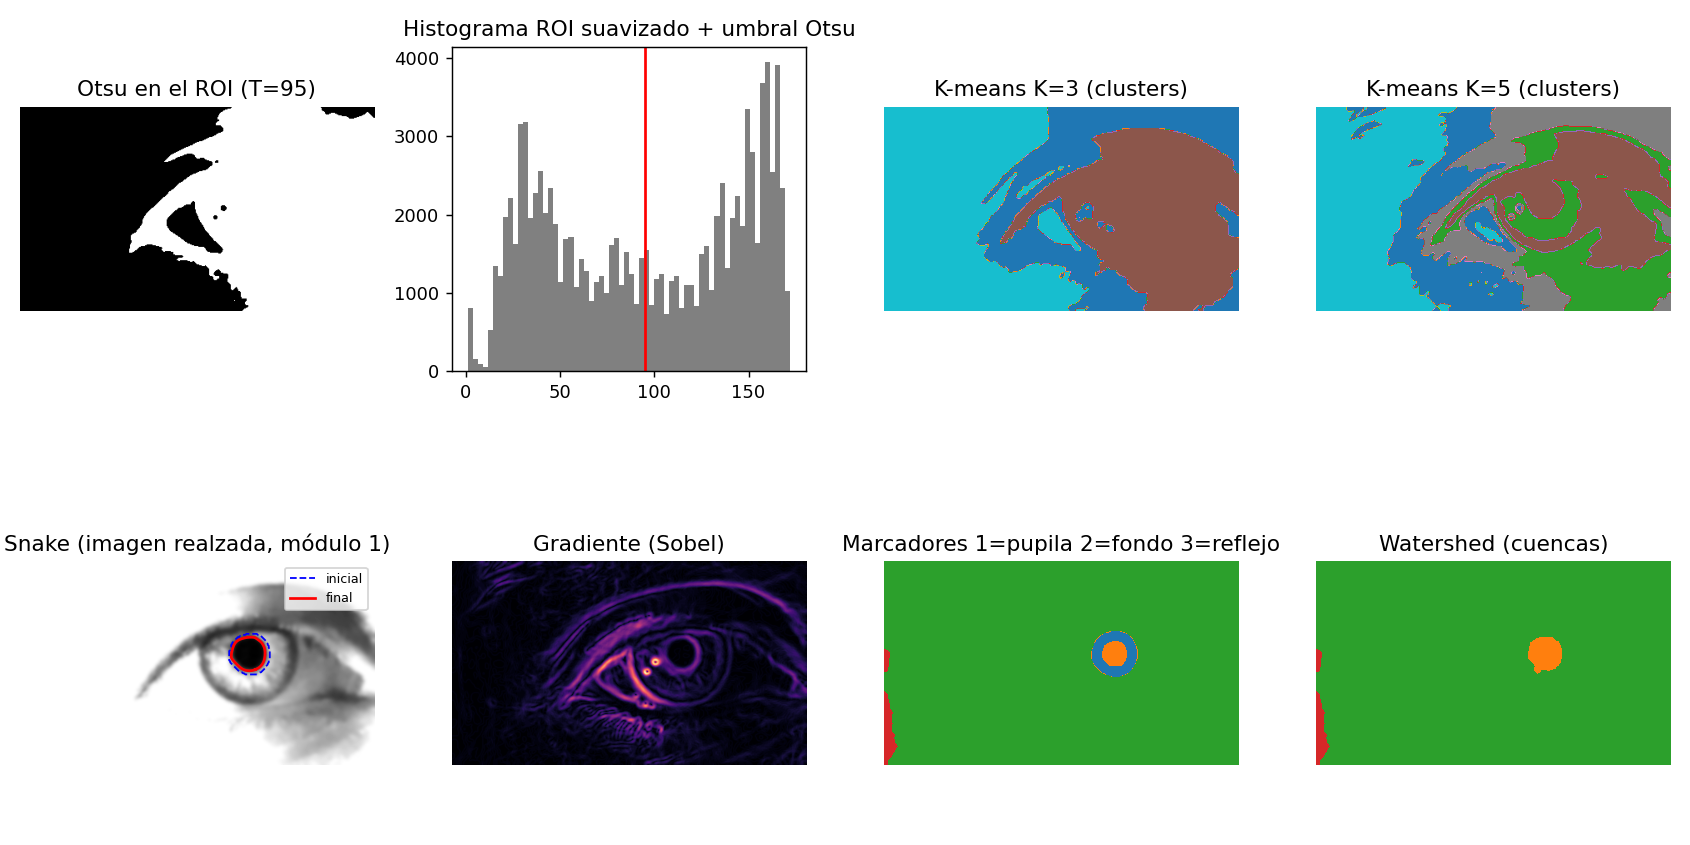

In [13]:
for patron in ("*_21_metodos.png", "*_21_diagnostico.png"):
    for archivo in sorted(m2.OUT_IMAGEN.glob(f"{stem}_frame_{patron}")):
        print(archivo.name)
        display(Image(filename=str(archivo)))

**Análisis.** _[completar con nuestros resultados: qué se lleva cada método además de la pupila (pestañas, sombra del párpado, iris oscuro) y cómo trata el reflejo corneal]_

### 4.3 Comparación de métodos en muchos frames

Un frame no alcanza para elegir: un método puede andar bien en el frame más limpio y fallar con un parpadeo parcial o después del estímulo. Se aplican los cinco métodos a los mismos conjuntos de frames de la sección 3.4, todos con la misma morfología del programa, y se mide lo mismo: frames válidos según el control de calidad, ruido en el tramo basal y tiempo. Para que la comparación sea pareja, el diámetro se mide igual en todos, como el diámetro equivalente al área de la máscara. No se usa el ancho horizontal de la máscara porque cambia de a un píxel entero y, en el tramo basal, ese escalón tapa el ruido que se quiere medir (el programa evita el problema midiendo el ancho sobre el contorno subpíxel de la snake).

El ruido solo se puede comparar entre métodos que segmentan lo mismo: un método que se lleva parte del iris puede ser muy estable y medir mal. Por eso hay que mirar también el gráfico (¿el diámetro coincide con el de la pupila?) y, si hay anotación manual, el Dice de la sección 7.

,Válidos (%),Ruido en el tramo basal (CV %),Tiempo por frame (ms)
metodo,,,
Snake (programa),96.64,3.82,52.72
Otsu global,0.00,NaN,12.10
Otsu multinivel,0.00,NaN,12.13
K-means (K = 3),0.00,NaN,80.71
Watershed,96.64,2.67,59.78


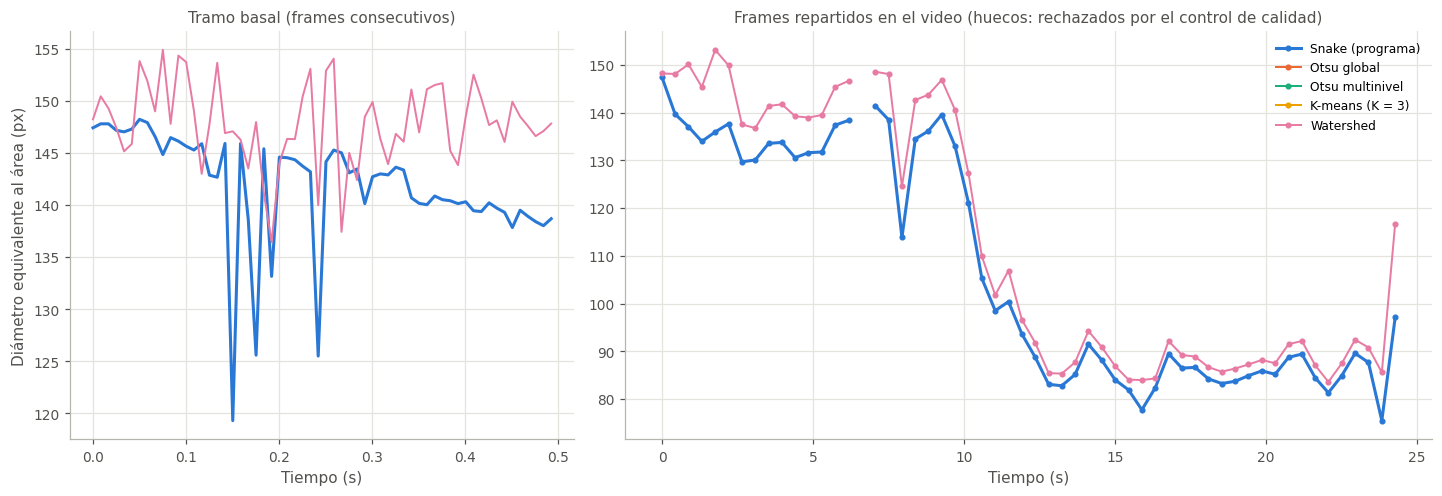

In [14]:
METODOS = ["Snake (programa)", "Otsu global", "Otsu multinivel", "K-means (K = 3)", "Watershed"]


def morfologia_programa(m, esc, semilla):
    # La combinación del programa: apertura, componente con la semilla, cierre y relleno de huecos
    se = disk(m2.px(2, esc))
    x = m2.componente_con_semilla(m2.binary_opening(m, se), semilla)
    return ndi.binary_fill_holes(m2.binary_closing(x, se))


def segmentar_metodos(crop, info):
    esc = info["esc"]
    m2.ESC = esc   # Los métodos de 2.1 toman de acá el tamaño de sus filtros
    mejora, (x, y, r0) = mejorar(crop, info)
    sl = (slice(None), slice(None))
    semilla = (int(round(x)), int(round(y)))
    alto, ancho = mejora["gris"].shape
    yy, xx = np.mgrid[:alto, :ancho]
    disco = np.hypot(xx - x, yy - y) <= max(r0, 2)   # Marcador del Watershed: la pupila estimada
    funciones = {
        "Snake (programa)": lambda: m2.segmentar_frame(mejora, (x, y), esc, r0=r0),
        "Otsu global": lambda: morfologia_programa(m2.seg_otsu(mejora["suave"], sl, semilla)[0], esc, semilla),
        "Otsu multinivel": lambda: morfologia_programa(m2.seg_otsu(mejora["suave"], sl, semilla)[2], esc, semilla),
        "K-means (K = 3)": lambda: morfologia_programa(m2.seg_kmeans(mejora["lab_suave"], sl, semilla, 3)[0], esc, semilla),
        "Watershed": lambda: morfologia_programa(m2.seg_watershed(mejora["suave"], sl, semilla, disco)[0], esc, semilla),
    }
    mascaras, tiempos = {}, {}
    for nombre, funcion in funciones.items():
        inicio = time.perf_counter()
        try:
            m = funcion()
        except ValueError:   # Frame sin contraste (p. ej. un parpadeo): el método no puede umbralizar
            m = None
        tiempos[nombre] = 1000 * (time.perf_counter() - inicio)
        mascaras[nombre] = np.zeros((alto, ancho), bool) if m is None else m
    return mejora, mascaras, tiempos


def evaluar_metodos(recortes):
    filas = []
    for i, (crop, info) in recortes.items():
        mejora, mascaras, tiempos = segmentar_metodos(crop, info)
        for nombre, m in mascaras.items():
            valido = m2.calidad(m, mejora, info["r_ref"])[0]
            d = 2 * np.sqrt(m.sum() / np.pi) / prep["factor"] if valido else np.nan   # Diámetro equivalente
            filas.append({"frame": i, "t": i / fps, "metodo": nombre, "valido": valido, "d": d, "ms": tiempos[nombre]})
    return pd.DataFrame(filas)


met_b, met_m = evaluar_metodos(recortes_basales), evaluar_metodos(recortes_muestras)
todos = pd.concat([met_b, met_m])
tabla_met = pd.DataFrame({
    "Válidos (%)": 100 * todos.groupby("metodo").valido.mean(),
    "Ruido en el tramo basal (CV %)": met_b.groupby("metodo").d.apply(ruido_cv),
    "Tiempo por frame (ms)": todos.groupby("metodo").ms.median(),
}).loc[METODOS].round(2)
display(tabla_met)

fig, (e1, e2) = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained", width_ratios=[1, 1.6])
for color, metodo in zip(COLORES, METODOS):
    b, m = met_b[met_b.metodo == metodo], met_m[met_m.metodo == metodo]
    ancho = 2 if metodo == "Snake (programa)" else 1.3
    e1.plot(b.t, b.d, "-", color=color, lw=ancho, label=metodo)
    e2.plot(m.t, m.d, "-o", color=color, ms=3, lw=ancho, label=metodo)
e1.set_title("Tramo basal (frames consecutivos)", fontsize=10, color=GRIS)
e2.set_title("Frames repartidos en el video (huecos: rechazados por el control de calidad)", fontsize=10, color=GRIS)
e1.set_ylabel("Diámetro equivalente al área (px)", color=GRIS)
for eje in (e1, e2):
    eje.set_xlabel("Tiempo (s)", color=GRIS)
    ejes(eje)
e2.legend(frameon=False, fontsize=8, loc="best")
plt.show()

**Por qué la snake.** Además de lo que muestre la tabla, la snake tiene ventajas que los métodos por píxel no tienen. Sus fuerzas internas mantienen el contorno cerrado y suave aunque haya pestañas o un reflejo sobre el borde, cuando un umbral deja muescas o puentes. Devuelve el contorno con precisión subpíxel, que es lo que permite medir el ancho horizontal sin el escalón de un píxel. Y puede partir del contorno del frame anterior, lo que le da continuidad temporal. Su costo es el tiempo: es el método más lento, por eso el programa reduce la resolución (sección 2).

**Análisis.** _[completar con nuestros resultados: qué método tiene más frames válidos y menos ruido; en qué frames fallan los métodos por píxel; si algún método sigue mejor la constricción; costo en tiempo de la snake]_

### 4.4 La snake en detalle

Parámetros de `active_contour`: elasticidad α = 0,1 / esc² (tiende a encoger el contorno), rigidez β = 1 / esc² (lo mantiene suave), paso γ = 0,01, atracción a los bordes w<sub>edge</sub> = 1 y a la intensidad w<sub>line</sub> = 0, hasta 2500 iteraciones. α y β se dividen por esc² porque la energía interna depende de las distancias entre puntos del contorno, que crecen con la resolución; sin esa corrección, a resolución alta la snake colapsa antes de llegar al borde.

El contorno inicial es un círculo de 1,3 veces la pupila estimada: queda afuera de la pupila y la snake se cierra sobre el borde, donde la fuerza de la imagen equilibra la elasticidad.

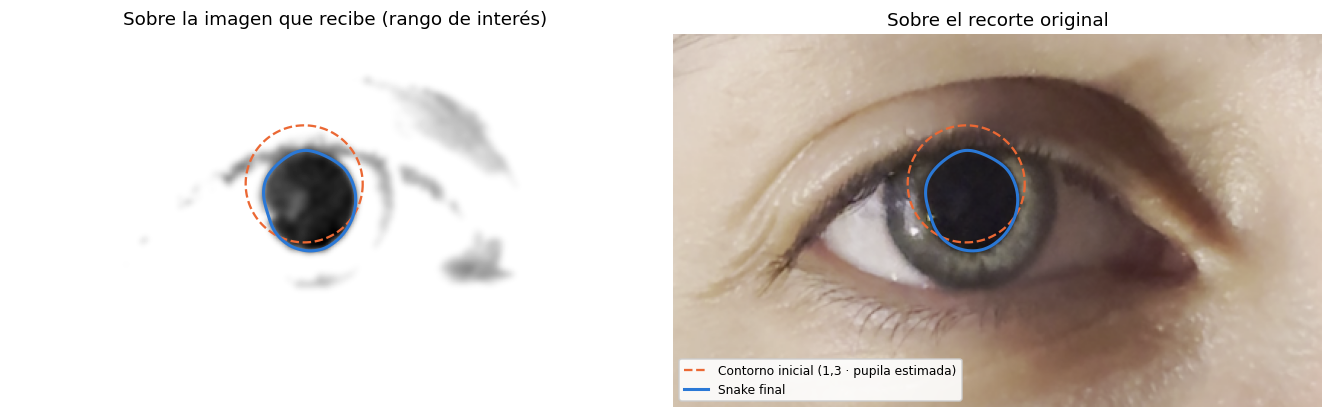

In [15]:
inicial = m2.circulo(x0, y0, 1.3 * rp0)
fig, (e1, e2) = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
e1.imshow(mejora0["realzada"], cmap="gray")
e2.imshow(a_rgb(recorte0))
for eje in (e1, e2):
    eje.plot(inicial[:, 1], inicial[:, 0], "--", color=COLORES[1], lw=1.5)
    if snake0 is not None:
        eje.plot(snake0[:, 1], snake0[:, 0], "-", color=COLORES[0], lw=2)
    eje.axis("off")
e1.set_title("Sobre la imagen que recibe (rango de interés)")
e2.set_title("Sobre el recorte original")
e2.legend(handles=[Line2D([], [], color=COLORES[1], ls="--", lw=1.5, label="Contorno inicial (1,3 · pupila estimada)"),
                   Line2D([], [], color=COLORES[0], lw=2, label="Snake final")],
          loc="lower left", fontsize=8, framealpha=0.9)
plt.show()

**Análisis.** _[completar con nuestros resultados: si la snake final sigue el borde de la pupila, también donde está el reflejo corneal o las pestañas]_

### 4.5 Morfología (2.2)

Sobre la máscara de la snake se aplica, con un disco de 2 px·esc:

1. **Apertura:** corta puentes finos hacia las pestañas o el pliegue del párpado.
2. **Componente conexa de la semilla:** descarta lo que quedó desconectado.
3. **Cierre:** tapa muescas del borde causadas por reflejos.
4. **Relleno de huecos:** incorpora a la pupila los reflejos que quedan completamente adentro.

La apertura va antes que el cierre porque, al revés, el cierre podría unir la pupila con una pestaña cercana antes de que la apertura la separe. Las figuras del programa comparan cada operación por separado y la combinación sobre la snake y sobre el mejor método por píxel, con los esqueletos (eje medio y contorno) de la máscara final.

registro_A1_frame_2935_22_morfologia_Otsu_multinivel.png


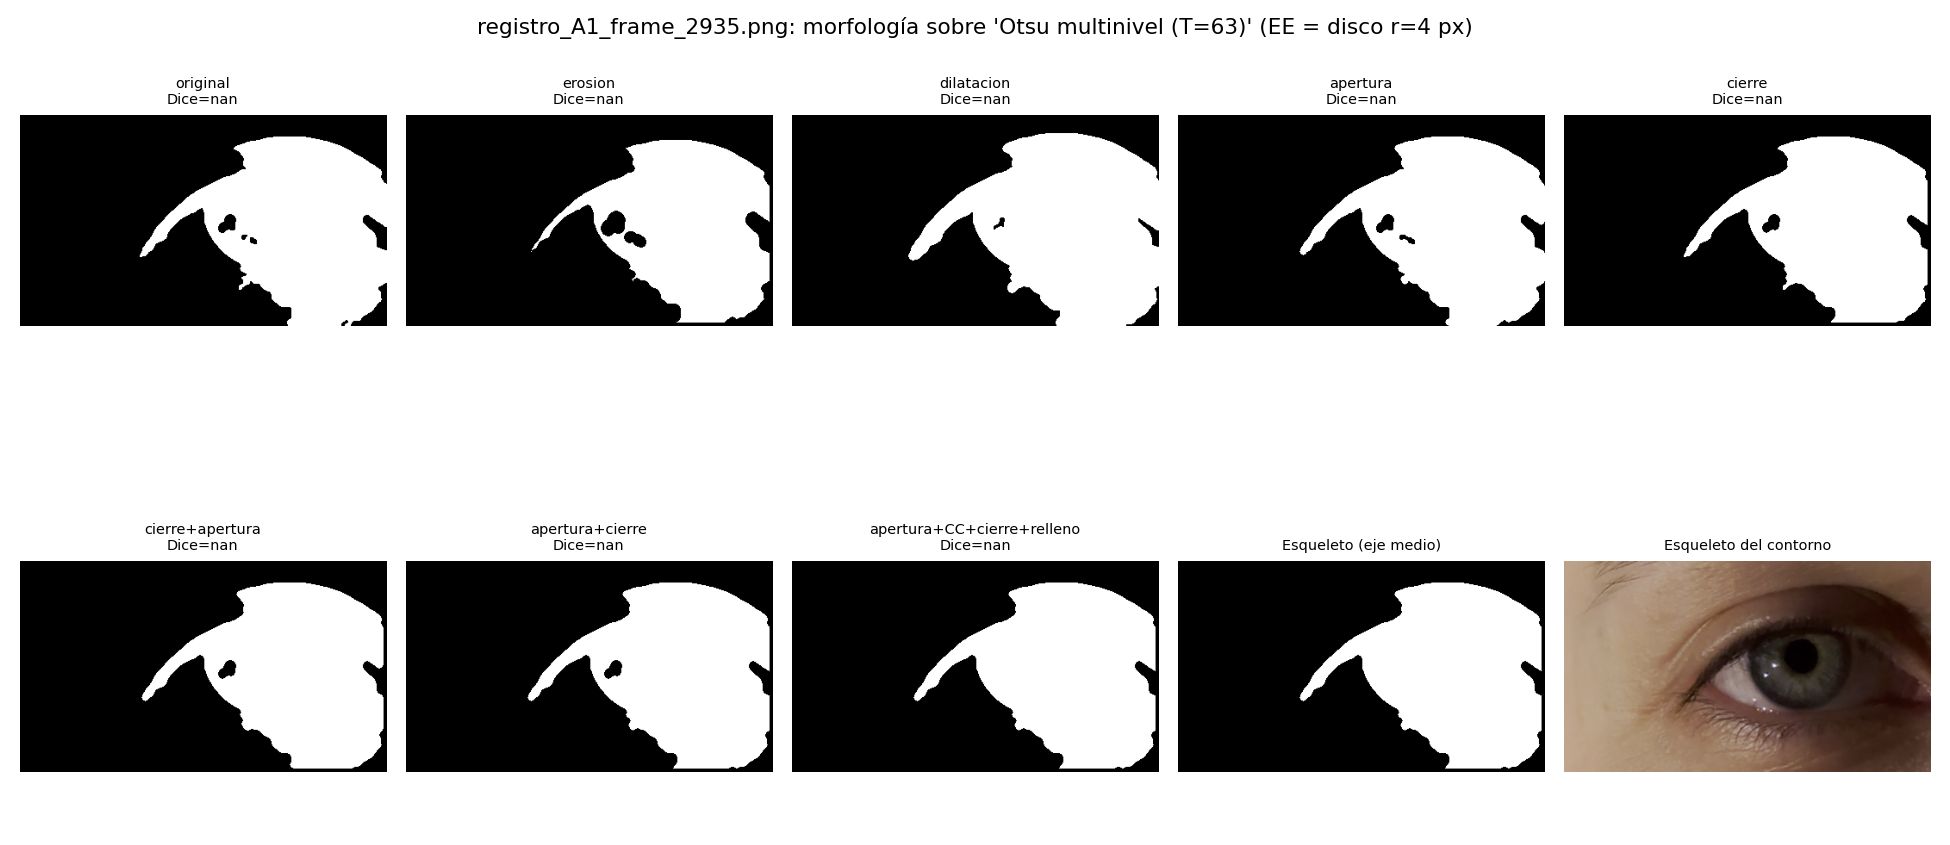

registro_A1_frame_2935_22_morfologia_Snake.png


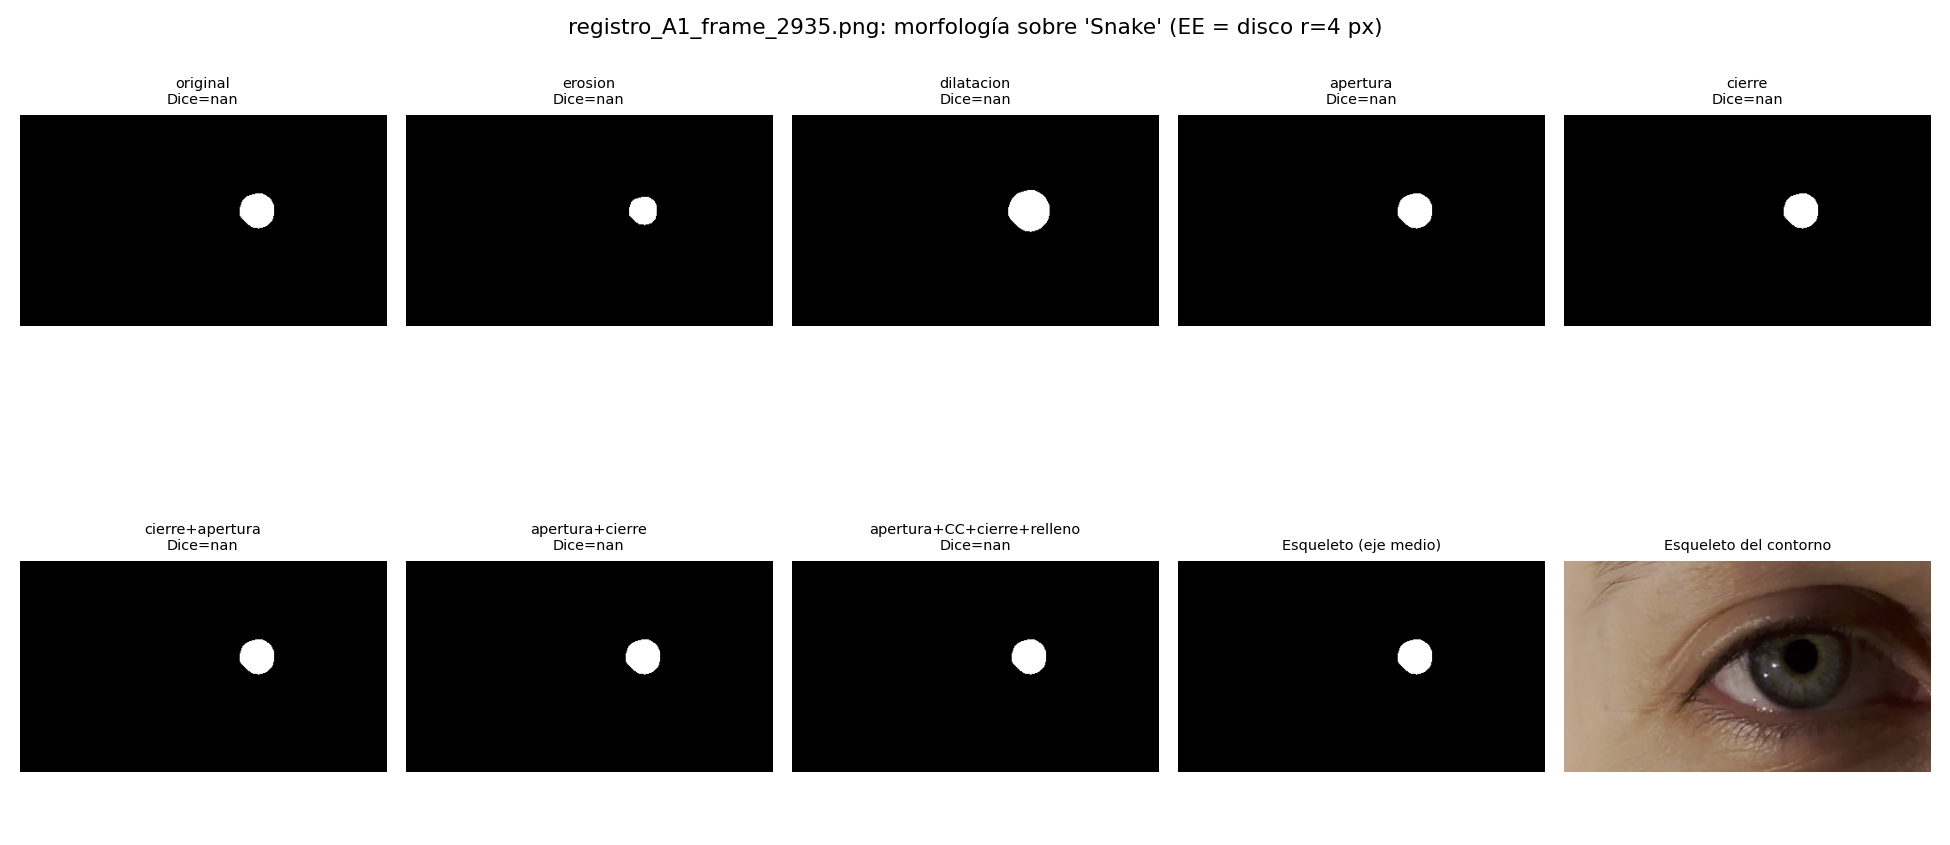

registro_A1_frame_2935_22_morfologia_Watershed.png


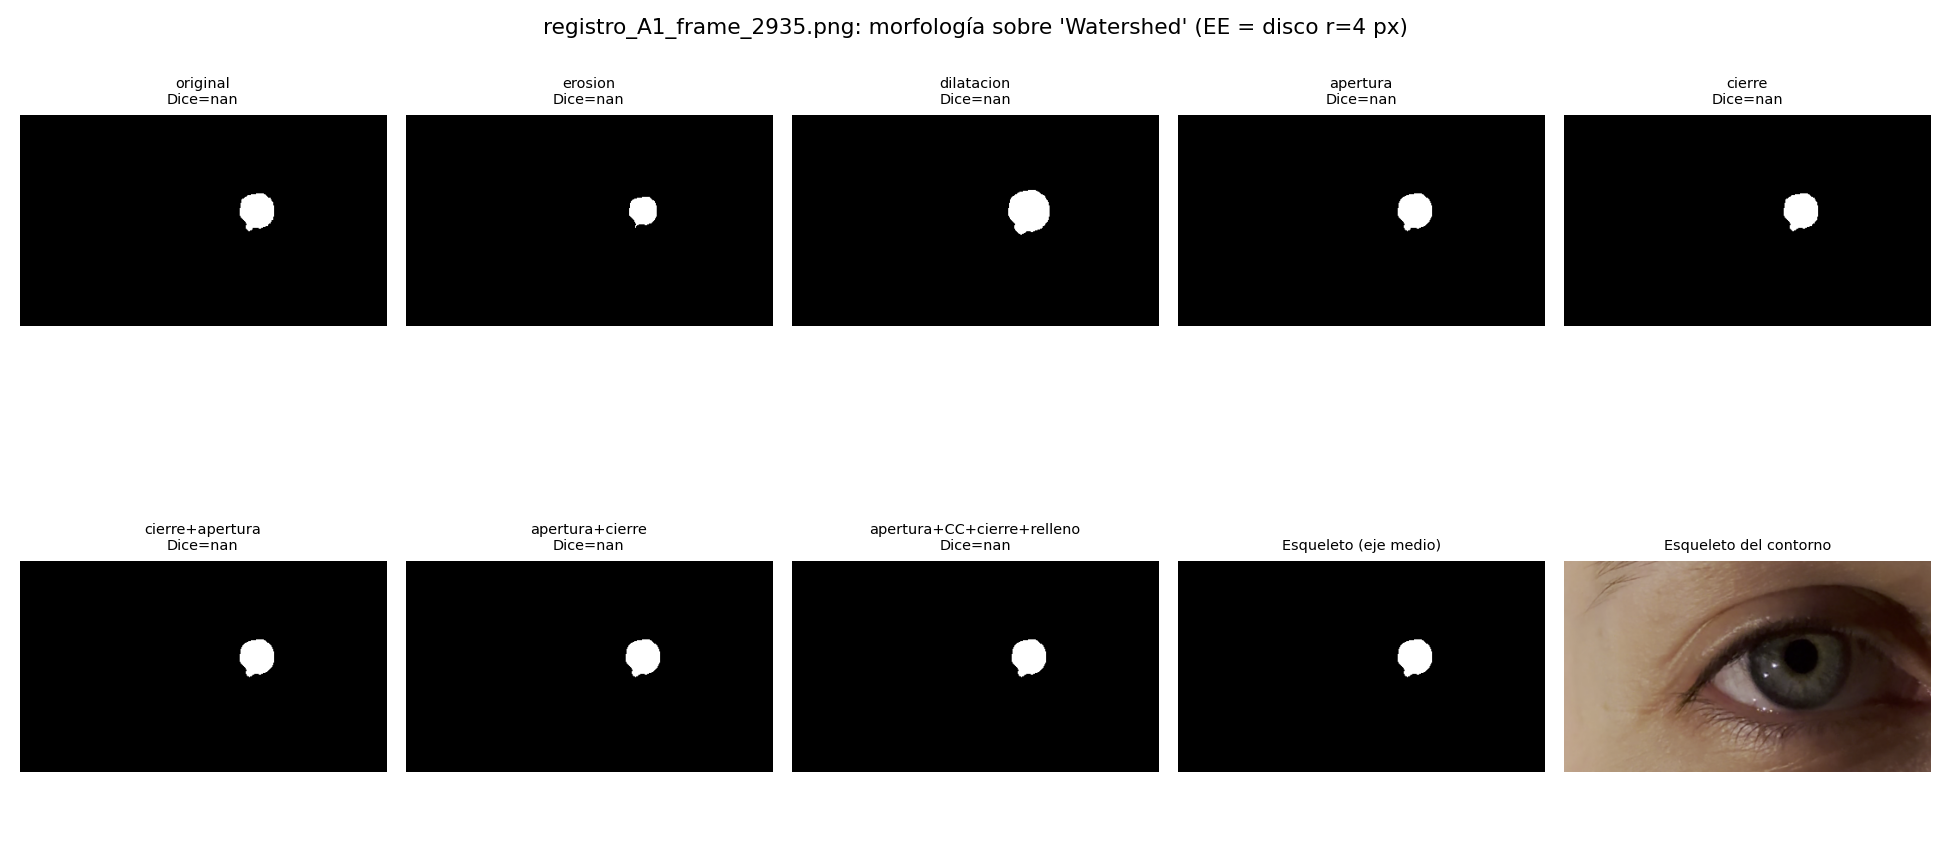

In [16]:
for archivo in sorted(m2.OUT_IMAGEN.glob(f"{stem}_frame_*_22_morfologia_*.png")):
    print(archivo.name)
    display(Image(filename=str(archivo)))

**Análisis.** _[completar con nuestros resultados: qué corrige cada operación en nuestras máscaras (puentes, muescas, reflejo) y cómo cambia el esqueleto]_

### 4.6 Control de calidad

Un frame se rechaza (queda en NaN y el módulo 3 lo interpola) si:

| Criterio | Umbral | Qué descarta |
|---|---|---|
| Tamaño | radio entre 10 % y 90 % del iris | ruido o una zona que no es la pupila |
| Circularidad | relación de ejes × solidez ≥ 0,65 | pupila tapada en parte, pestañas pegadas |
| Oscuridad | media de la máscara ≤ F2 + 15 | parpadeo: la snake encierra piel |
| Contraste con el anillo que la rodea | ≥ 20 niveles | sombra o párpado cerrado |
| Borde del ROI | la máscara no lo toca | ojo fuera del recorte |

Se muestra un ejemplo de cada motivo que apareció, tomado del video de control que genera el programa (contorno verde: válido; rojo: rechazado).

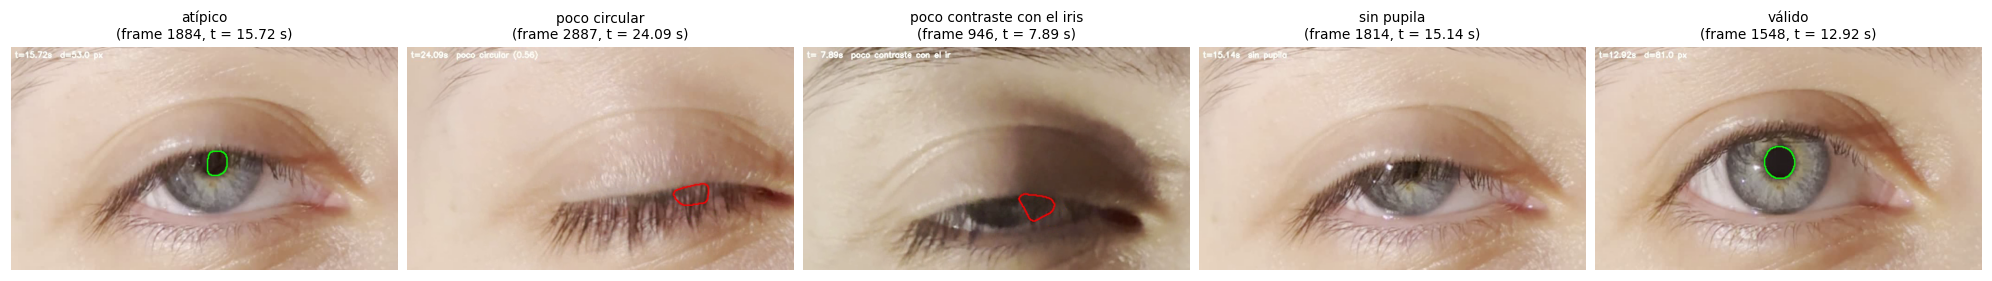

In [17]:
video_control = m2.OUT_VIDEO / f"{stem}_overlay.mp4"
ejemplos = {}
for motivo, grupo in serie.groupby("motivo_corto"):
    ejemplos[motivo] = int(grupo.frame.iloc[len(grupo) // 2])
imagenes = leer_frames(ejemplos.values(), video=video_control)
n = len(ejemplos)
fig, ejes_c = plt.subplots(1, n, figsize=(3.6 * n, 3.4), layout="constrained", squeeze=False)
for eje, (motivo, i) in zip(ejes_c[0], ejemplos.items()):
    if i in imagenes:
        eje.imshow(a_rgb(imagenes[i]))
    eje.set_title(f"{motivo}\n(frame {i}, t = {i / fps:.2f} s)", fontsize=9)
    eje.axis("off")
plt.show()

**Análisis.** _[completar con nuestros resultados: si los rechazos son correctos (parpadeos, pupila tapada) o si se descartan frames que estaban bien]_

### 4.7 Diámetro horizontal vs diámetro equivalente

El programa usa como diámetro el ancho horizontal máximo de la pupila, no el diámetro del círculo de igual área. Los párpados tapan la pupila desde arriba y desde abajo: cuando la cubren en parte, el área baja aunque la pupila no haya cambiado, mientras que el ancho horizontal sigue igual mientras el párpado no llegue al centro.

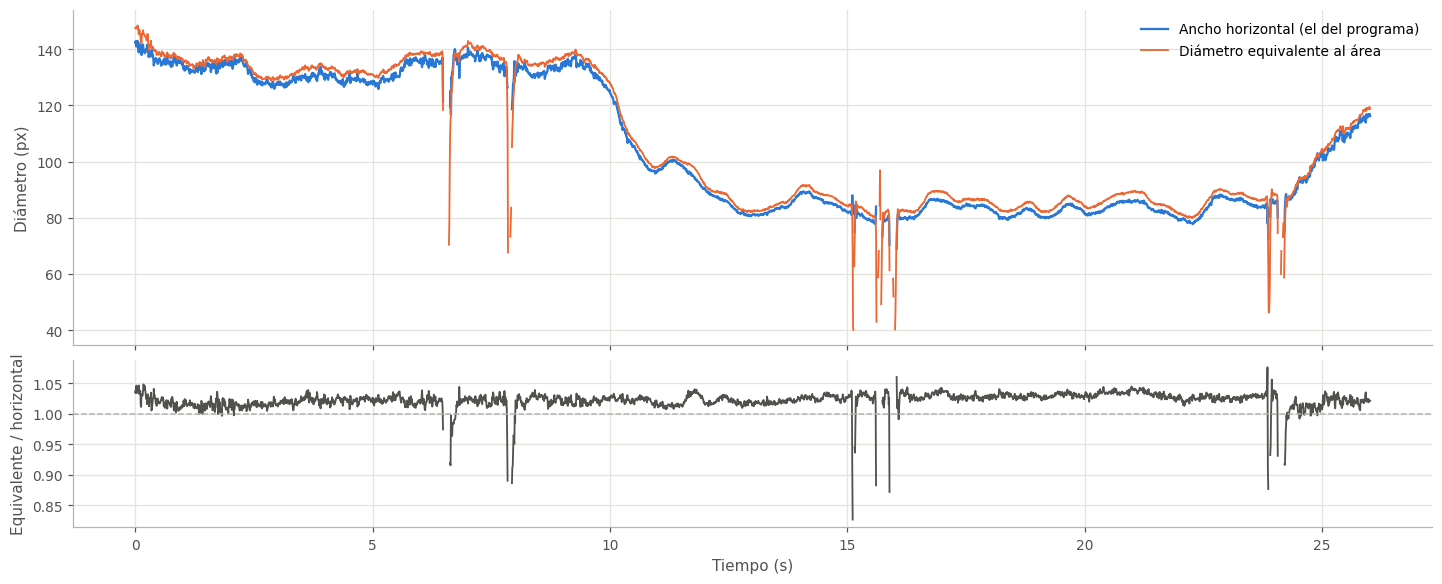

In [18]:
fig, (e1, e2) = plt.subplots(2, 1, figsize=(13, 5.2), sharex=True, layout="constrained", height_ratios=[2, 1])
e1.plot(serie.t, serie.d_pupila_px, color=COLORES[0], lw=1.5, label="Ancho horizontal (el del programa)")
e1.plot(serie.t, serie.d_area_px, color=COLORES[1], lw=1.2, label="Diámetro equivalente al área")
e1.set_ylabel("Diámetro (px)", color=GRIS)
e1.legend(frameon=False, fontsize=9)
e2.plot(serie.t, serie.d_area_px / serie.d_pupila_px, color=GRIS, lw=1.2)
e2.axhline(1, color=m1.GRIS_EJES, lw=1, ls="--")
e2.set_ylabel("Equivalente / horizontal", color=GRIS)
e2.set_xlabel("Tiempo (s)", color=GRIS)
for eje in (e1, e2):
    ejes(eje)
plt.show()

**Análisis.** _[completar con nuestros resultados: cuánto difieren las dos medidas, en qué momentos el diámetro equivalente cae y el horizontal no (párpado)]_

## 5. Curva temporal (Módulo 3)

### 5.1 Artefactos e interpolación

Además de los frames que rechazó el módulo 2, se marcan como artefacto los frames con:

- **circularidad < 0,6** (parpadeo, pestañas);
- **movimiento del centroide > 5 diámetros/s**, medido en 50 ms (lo que dura una sacada; entre frames consecutivos el temblor normal de la segmentación ya daría velocidades altas a 120 fps);
- **atípicos según el filtro de Hampel:** se apartan de la mediana de una ventana de 0,6 s más de 3 desvíos robustos (1,4826·MAD, con un piso del 1 % de la mediana para tramos muy estables). La mediana y el MAD no se dejan arrastrar por los valores atípicos, a diferencia de la media y el desvío. La ventana de 0,6 s es más del doble de lo que dura un parpadeo (0,1 a 0,3 s), así que la mediana no lo sigue.

Cada tramo marcado se ensancha 50 ms de cada lado, porque al empezar y terminar un parpadeo la pupila ya está tapada en parte. Los frames marcados se reemplazan por interpolación lineal en el tiempo.

Módulo 2: 3042 de 3118 frames válidos
     33  atípico
     21  sin pupila
     15  poco contraste con el iris
      7  poco circular
Artefactos: 219 de 3118 frames (7.0%); 25 por el filtro de Hampel, 28 por movimiento del centroide


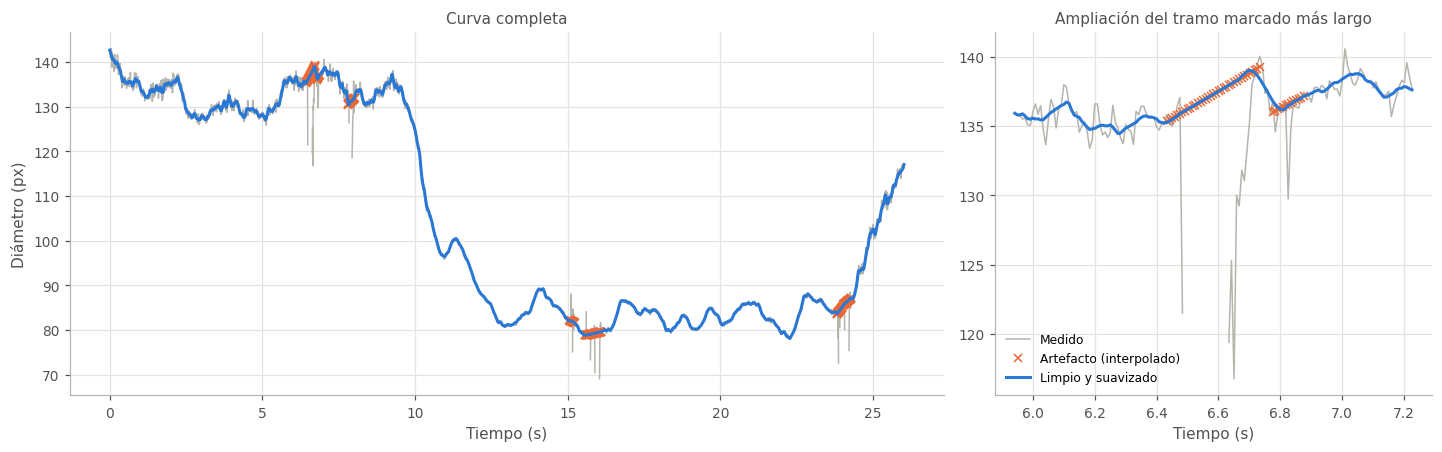

In [19]:
curva = m3.curva_desde_modulo2(filas, ruta, r_iris)
curva = m3.limpiar_curva(curva)

art = curva["artefacto"].to_numpy()
cambios = np.flatnonzero(np.diff(np.r_[0, art.astype(int), 0]))
tramos = list(zip(cambios[::2], cambios[1::2]))   # [inicio, fin) de cada tramo marcado
fig, ejes_a = plt.subplots(1, 2 if tramos else 1, figsize=(13, 4), layout="constrained", squeeze=False,
                           width_ratios=[2, 1] if tramos else None)
ventanas = [(curva.t_s.min(), curva.t_s.max())]
if tramos:
    a, b = max(tramos, key=lambda tr: tr[1] - tr[0])
    ventanas.append((curva.t_s.iloc[a] - 0.5, curva.t_s.iloc[b - 1] + 0.5))
for eje, (t_a, t_b) in zip(ejes_a[0], ventanas):
    c = curva[(curva.t_s >= t_a) & (curva.t_s <= t_b)]
    eje.plot(c.t_s, c.diametro, color=m1.GRIS_EJES, lw=1, label="Medido")
    eje.plot(c.t_s[c.artefacto], c.diametro_limpio[c.artefacto], "x", color=COLORES[1], ms=5, label="Artefacto (interpolado)")
    eje.plot(c.t_s, c.diametro_suave, color=COLORES[0], lw=2, label="Limpio y suavizado")
    eje.set_xlabel("Tiempo (s)", color=GRIS)
    ejes(eje)
ejes_a[0][0].set_ylabel("Diámetro (px)", color=GRIS)
ejes_a[0][0].set_title("Curva completa", fontsize=10, color=GRIS)
if tramos:
    ejes_a[0][1].set_title("Ampliación del tramo marcado más largo", fontsize=10, color=GRIS)
ejes_a[0][-1].legend(frameon=False, fontsize=8)
plt.show()

**Análisis.** _[completar con nuestros resultados: cuántos frames se marcaron y por qué criterio; si la interpolación sobre el parpadeo queda razonable]_

### 5.2 Suavizado de Savitzky-Golay

La curva limpia se suaviza con un filtro de Savitzky-Golay (polinomio de grado 2 en ventanas de 0,15 s). Ajustar un polinomio permite seguir la curvatura del mínimo de la constricción, mientras que una media móvil lo aplana y subestima la amplitud. Cuánto importa depende del largo de la ventana frente a la duración del mínimo, así que se comparan los dos filtros con la ventana del programa y con una de 0,5 s.

,Mínimo (px)
Curva limpia (sin suavizar),77.98
"Savitzky-Golay, 0.15 s (19 muestras)",78.10
"Media móvil, 0.15 s (19 muestras)",78.33
"Savitzky-Golay, 0.5 s (61 muestras)",78.42
"Media móvil, 0.5 s (61 muestras)",79.06


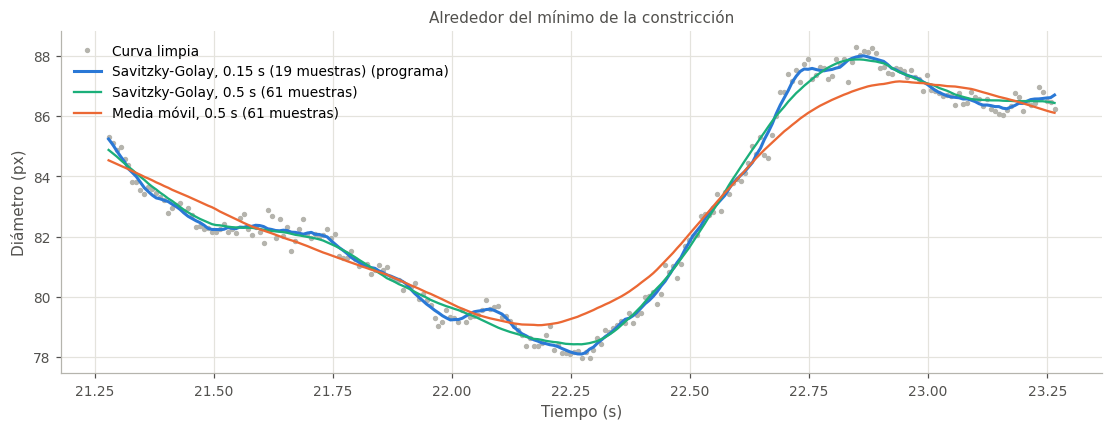

In [20]:
from scipy.signal import savgol_filter

dt = np.median(np.diff(curva.t_s))
limpia = curva.diametro_limpio
i_min = curva.diametro_suave.idxmin()
t_min = curva.t_s[i_min]
cerca = (curva.t_s - t_min).abs() <= 0.5
filas_sg = {"Curva limpia (sin suavizar)": limpia}
for segundos in (0.15, 0.5):
    v = m3.a_muestras(segundos, dt, minimo=5, impar=True)
    filas_sg[f"Savitzky-Golay, {segundos} s ({v} muestras)"] = pd.Series(savgol_filter(limpia, v, 2), index=limpia.index)
    filas_sg[f"Media móvil, {segundos} s ({v} muestras)"] = limpia.rolling(v, center=True, min_periods=1).mean()
display(pd.DataFrame({"Mínimo (px)": {k: c[cerca].min() for k, c in filas_sg.items()}}).round(2))

nombres = list(filas_sg)
zona = (curva.t_s - t_min).abs() <= 1.0
fig, eje = plt.subplots(figsize=(10, 3.8), layout="constrained")
eje.plot(curva.t_s[zona], limpia[zona], ".", color=m1.GRIS_EJES, ms=5, label="Curva limpia")
eje.plot(curva.t_s[zona], filas_sg[nombres[1]][zona], color=COLORES[0], lw=2, label=nombres[1] + " (programa)")
eje.plot(curva.t_s[zona], filas_sg[nombres[3]][zona], color=COLORES[2], lw=1.5, label=nombres[3])
eje.plot(curva.t_s[zona], filas_sg[nombres[4]][zona], color=COLORES[1], lw=1.5, label=nombres[4])
eje.set_title("Alrededor del mínimo de la constricción", fontsize=10, color=GRIS)
eje.set_xlabel("Tiempo (s)", color=GRIS)
eje.set_ylabel("Diámetro (px)", color=GRIS)
eje.legend(frameon=False, fontsize=9)
ejes(eje)
plt.show()

**Análisis.** _[completar con nuestros resultados: cuántos píxeles de amplitud pierde cada filtro respecto de la curva limpia, con la ventana del programa y con la larga]_

### 5.3 Velocidad

Las velocidades de constricción y redilatación salen de la derivada del diámetro. Derivar amplifica el ruido de alta frecuencia: con diferencias entre frames, el temblor de la segmentación da velocidades del mismo orden que la constricción. El programa deriva con un filtro de Savitzky-Golay de 0,3 s (ajusta un polinomio en cada ventana y deriva el polinomio). La ventana es un compromiso: más larga reduce más el ruido pero aplana el pico de velocidad. Abajo se comparan los dos picos.

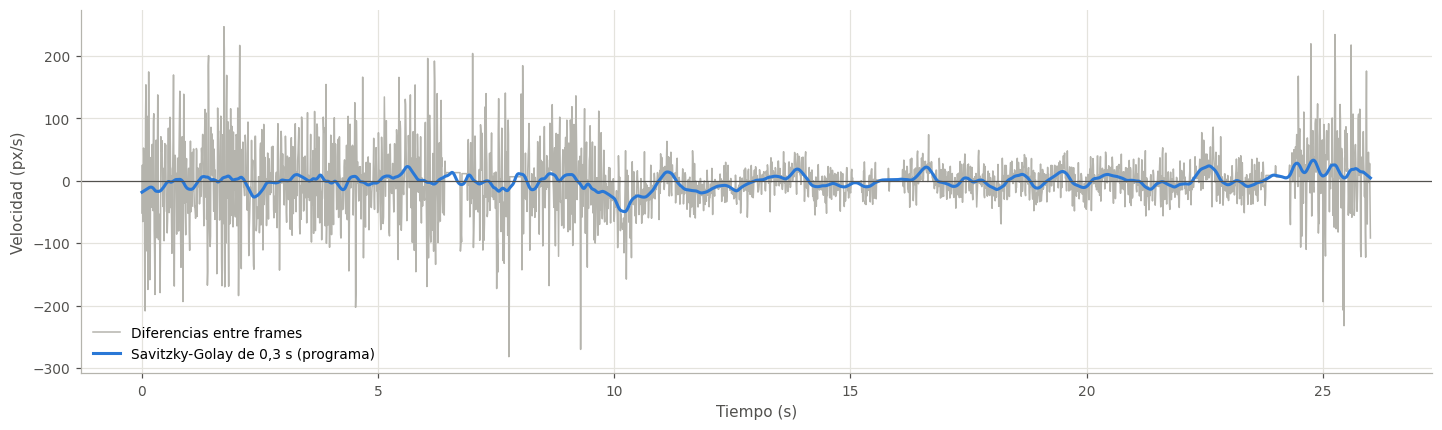

Pico de constricción: -282.0 px/s con diferencias, -49.6 px/s con Savitzky-Golay
Desvío de la velocidad en el tramo basal con diferencias: 80.6 px/s


In [21]:
v_dif = np.gradient(curva.diametro_limpio, curva.t_s)
v_sg = m3.velocidad_suavizada(curva.t_s, curva.diametro_suave)
fig, eje = plt.subplots(figsize=(13, 3.8), layout="constrained")
eje.plot(curva.t_s, v_dif, color=m1.GRIS_EJES, lw=1, label="Diferencias entre frames")
eje.plot(curva.t_s, v_sg, color=COLORES[0], lw=2, label="Savitzky-Golay de 0,3 s (programa)")
eje.axhline(0, color=GRIS, lw=0.8)
eje.set_xlabel("Tiempo (s)", color=GRIS)
eje.set_ylabel("Velocidad (px/s)", color=GRIS)
eje.legend(frameon=False, fontsize=9)
ejes(eje)
plt.show()
ruido_basal = np.std(v_dif[curva.t_s < SEGUNDOS_BASALES])
print(f"Pico de constricción: {v_dif.min():.1f} px/s con diferencias, {v_sg.min():.1f} px/s con Savitzky-Golay")
print(f"Desvío de la velocidad en el tramo basal con diferencias: {ruido_basal:.1f} px/s")

**Análisis.** _[completar con nuestros resultados: cuánto ruido tienen las diferencias en el tramo basal frente al pico de constricción, y cuánto se reduce el pico con la derivada suavizada]_

## 6. Estímulo y parámetros fisiológicos (Módulo 3)

**Estímulo.** Para cada instante se compara el brillo medio del frame en el segundo siguiente con el del segundo anterior: un escalón sostenido es un cambio de iluminación, y no un parpadeo o una mano que pasa. Son candidatos los escalones de al menos el 30 % del mayor, separados por 2 s o más. El estímulo empieza cuando el brillo se aparta del nivel previo más del 10 % del escalón (el encendido es una rampa, por la linterna y la exposición automática de la cámara). Se elige el primer candidato después del cual la pupila responde al menos un 10 % en el sentido esperado: contracción si la luz subió, dilatación si bajó. Así no se toma como estímulo apagar la linterna al terminar.

**Parámetros:**

- **Diámetro basal:** promedio del segundo previo al estímulo.
- **Extremo:** mínimo (o máximo, en una dilatación) en los 5 s siguientes. **Amplitud** = |extremo − basal|, en diámetro y en área, absoluta y relativa al basal.
- **Inicio de la respuesta y latencia:** desde el pico de velocidad se retrocede hasta que la pupila vuelve a estar a menos del 10 % de la amplitud del basal. Es más robusto que buscar hacia adelante desde el estímulo, donde el ruido puede cruzar el umbral. Latencia = inicio − estímulo.
- **Velocidades** máxima y media de constricción (entre el inicio y el mínimo) y de redilatación (en los 5 s posteriores al mínimo).
- **Recuperación:** porcentaje de la amplitud recuperado al final de esa ventana.

Las longitudes quedan en píxeles: el radio de iris del módulo 2 no es una medición, así que no se usa como escala.

Candidatos a estímulo:
  t =   9.58 s  escalón de brillo =  +10.8  respuesta (contraccion) = +21.3%
  t =  11.89 s  escalón de brillo =   -7.8  respuesta (dilatacion) = -14.5%
  t =  24.14 s  escalón de brillo =  -21.7  respuesta (dilatacion) = +23.2%


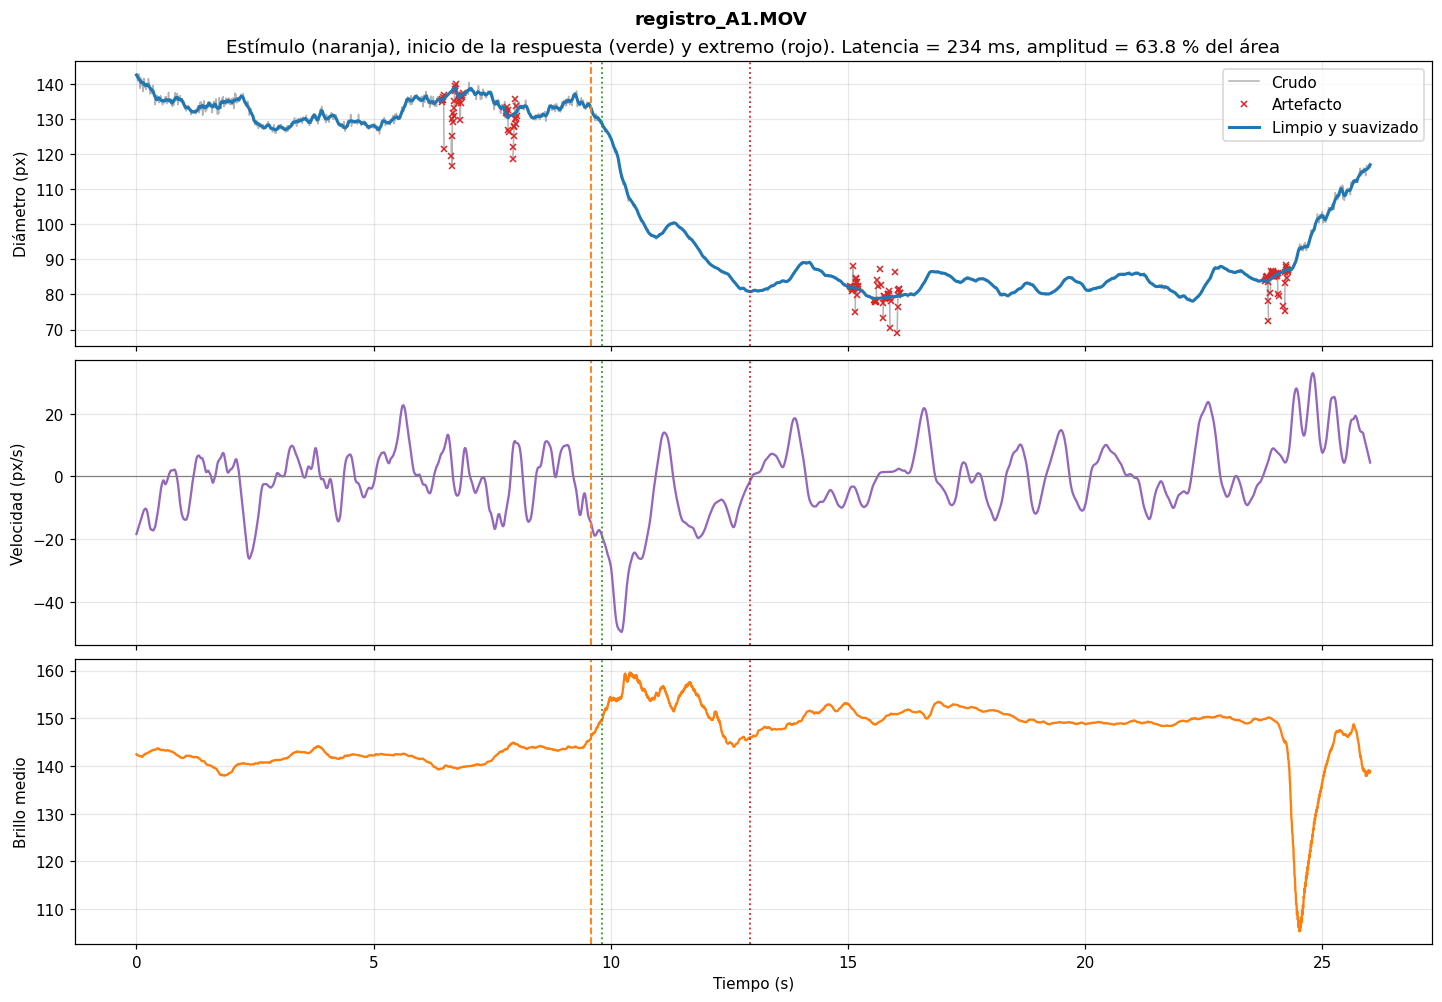

,Valor
Tipo de registro,contracción (luz encendida)
Estímulo,"9,58 s"
Latencia,234 ms
Diámetro basal → extremo,"134,1 → 80,8 px"
Amplitud (diámetro),"39,8 %"
Amplitud (área),"63,8 %"
Tiempo de respuesta,"3,13 s"
Velocidad de constricción,"máx 49,6 | media 17,0 px/s"
Velocidad de redilatación,"máx 21,8 | media 0,7 px/s"
Recuperación,"6,6 %"


Guardados en resultados\por_video\registro_A1: curva_temporal.csv y parametros_fisiologicos.csv


In [22]:
t_estimulo, tipo = m3.detectar_estimulo(curva)
parametros = m3.parametros_fisiologicos(curva, t_estimulo, tipo, mm_por_px=pipeline.MM_POR_PX)
m3.mostrar_curva(curva, parametros=parametros, titulo=ruta.name)
display(pd.Series(ui.parametros_legibles(parametros), name="Valor").to_frame())
m3.guardar_resultados(curva, parametros, pipeline.RAIZ / pipeline.CARPETA_RESULTADOS / "por_video" / stem)

**Análisis.** _[completar con nuestros resultados: si el estímulo detectado coincide con el encendido de la luz; valores de latencia, amplitud y velocidades y si están en el rango esperable para el reflejo fotomotor]_

## 7. Validación contra anotación manual

La consigna pide validar el diámetro automático contra una medición manual (MAE y RMSE, 3.2) y comparar los métodos de segmentación con Dice o IoU (2.2). El programa guarda frames equiespaciados del video en `resultados/resultados_modulo2/resultados_video/frames/`. Para anotarlos (se marca el borde de la pupila con clics y Enter), desde la carpeta del proyecto:

```
python modulos/modulo2_segmentacion.py --anotar resultados/resultados_modulo2/resultados_video/frames/<video>_frame_XXXX.png
```

Los contornos quedan en `anotaciones_manuales/referencias.json`. Esta sección los usa si existen; las figuras de 2.1 y 2.2 también muestran Dice e IoU al volver a correr el programa.

In [23]:
refs = {k: v for k, v in m2.cargar_refs().items() if k.startswith(f"{stem}_frame_")}
if not refs:
    print(f"No hay frames anotados de {ruta.name} en anotaciones_manuales/referencias.json")
else:
    anotados = {int(k.split("_frame_")[1].split(".")[0]): np.asarray(v, float) for k, v in refs.items()}
    recortes_ref = leer_frames(anotados, funcion=recortar)
    errores, solapamiento = [], []
    for i, pts in sorted(anotados.items()):
        d_manual = m2.ancho_horizontal(pts[:, ::-1])   # Puntos (x, y) -> (fila, columna)
        d_auto = serie.loc[serie.frame == i, "d_pupila_px"].iloc[0]
        errores.append({"frame": i, "Manual (px)": d_manual, "Programa (px)": d_auto, "Error (px)": d_auto - d_manual})
        crop, info = recortes_ref[i]
        _, mascaras, _ = segmentar_metodos(crop, info)
        referencia = m2.ref_en_recorte(pts, info, crop.shape)
        for metodo, m in mascaras.items():
            solapamiento.append({"Método": metodo, "Dice": m2.dice(m, referencia), "IoU": m2.iou(m, referencia)})
    errores = pd.DataFrame(errores).set_index("frame")
    display(errores.round(2))
    e = errores["Error (px)"].dropna()
    print(f"MAE = {e.abs().mean():.2f} px   RMSE = {np.sqrt((e ** 2).mean()):.2f} px   ({len(e)} frames con diámetro válido)")
    display(pd.DataFrame(solapamiento).groupby("Método").mean().loc[METODOS].round(3))

No hay frames anotados de registro_A1.MOV en anotaciones_manuales/referencias.json


**Análisis.** _[completar con nuestros resultados: MAE y RMSE en px y en % del diámetro; qué método tiene mayor Dice e IoU y si coincide con lo visto en 4.3]_

## 8. Resumen de decisiones

| Etapa | Elegimos | Descartamos | Por qué (sección) |
|---|---|---|---|
| ROI | manual, fijo en todo el video | detección automática del ojo | error controlado, el ojo casi no se mueve (2) |
| Escala | parámetros proporcionales al iris estimado | parámetros fijos en px | mismo comportamiento en cualquier resolución (2) |
| Resolución | iris de 64 px de radio como máximo | resolución original | mucho más rápido, diámetro casi igual (2) |
| Suavizado | gaussiano de 5 px·esc | sin suavizar, mediana, CLAHE | rango de captura de la snake, ruido (3.4) |
| Contraste | rango de interés [0, F2], F2 por Otsu multinivel en cada frame | rango fijo, ecualización | deja un solo borde fuerte y se adapta a la luz (3.2, 3.3) |
| Segmentación | snake con el contorno del frame anterior | Otsu, K-means, Watershed | contorno cerrado y subpíxel, continuidad temporal (4.3) |
| Morfología | apertura → componente de la semilla → cierre → relleno | operaciones sueltas | corta puentes, tapa muescas y reflejos (4.5) |
| Diámetro | ancho horizontal máximo | diámetro equivalente al área | no lo afecta el párpado (4.7) |
| Limpieza | Hampel + circularidad + movimiento, interpolación lineal | media y desvío comunes | robusto a los propios artefactos (5.1) |
| Suavizado de la curva | Savitzky-Golay de 0,15 s | media móvil | conserva el mínimo (5.2) |
| Velocidad | derivada de Savitzky-Golay de 0,3 s | diferencias entre frames | el ruido no tapa el pico (5.3) |

**Limitaciones.**

- El ROI hay que marcarlo una vez por video.
- Los resultados quedan en píxeles: para pasarlos a milímetros hace falta calibrar con una referencia filmada a la misma distancia (por ejemplo, una regla).
- La validación depende de cuántos frames se anoten a mano.